# Can descriptions predict my enjoyment beyond genre labels?

Hi Prof Watson. By the end of this semester, I want a project that can help me discover films and series for my watchlist and choose something that matches the moment. I might ask for the shrewdness of *Wednesday*, the medieval setting of *Merlin* or *Legend of the Seeker*, or the comedy I enjoyed in Chaplin's *The Great Dictator*. In my experience, a story is more enjoyable when it matches what I feel like watching.

This first pipeline tests one smaller question: **do short plot descriptions improve prediction of my overall liking beyond broad genre labels alone?** Current mood is not measured here, so this experiment cannot yet establish whether a system can choose the right film for a particular evening.

The notebook connects source records, cleaning decisions, mathematics, held-out predictions, and interpretation. Outputs are generated from preserved local data and a frozen evaluation procedure. The accompanying Python modules contain the reusable implementation.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

def find_pipeline_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in [base, base / "first_pipeline"]:
            if (candidate / "data/processed/model_dataset_v2.csv").is_file():
                return candidate.resolve()
    raise FileNotFoundError("Run from this project or its notebook directory.")

ROOT = find_pipeline_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from scipy.special import softmax
from src.experiments_v2 import load_data, freeze_protocol, run_all
from src.visuals_v2 import make_figures

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 15)

def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))

def show_percent(frame, columns):
    result = frame.copy()
    for column in columns:
        result[column] = 100 * result[column]
    display(result.style.format({column: "{:.2f}" for column in columns}))

data = load_data()  # Validates the 204 eligible rows; no model is fitted.
ratings = pd.read_csv(ROOT / "data/processed/ratings_v2.csv", keep_default_na=False)
metadata = pd.read_csv(ROOT / "data/processed/title_metadata_v2.csv", keep_default_na=False)
import unicodedata
synopsis_rows = read_json("data/raw/imdb_synopses_ui_2026-10-17.json")["rows"]
synopsis_rows += read_json("data/raw/imdb_chaplin_synopses_ui_2026-10-17.json")["rows"]
synopses_by_id = {row["imdb_id"]: row["synopsis"] for row in synopsis_rows}
assert len(synopses_by_id) == 335
synopsis_audit = {
    "raw_row_count": len(synopses_by_id), "selected_row_count": len(metadata),
    "normalized_text_changes": sum(
        text != " ".join(unicodedata.normalize("NFC", text).split())
        for text in synopses_by_id.values()),
}

assert set(data.record_id) == set(ratings.loc[ratings.rating > 0, "record_id"])
assert set(data.rating) == {1, 2, 3, 4}
print("Loaded preserved processed records. No vocabulary, topics, classifier, or tuning has been fitted.")

Loaded preserved processed records. No vocabulary, topics, classifier, or tuning has been fitted.


## From a personal collection to preference observations

A watchlist mixes things I watched with things I only intend to watch. Netflix history contributes viewing events, while HBO and Disney+ lists contribute saved titles. None of these records supplies an enjoyment label. I supplied ratings separately: **0 means not watched sufficiently to rate; 1–4 mean increasing liking**. Blank would mean pending, not zero. The levels have an order; their psychological gaps need not be equal.

One film or series is one observation. Hundreds of episodes share characters and an overall preference judgment, so counting each episode as a fresh independent preference would exaggerate the evidence. Even after this consolidation, sequels and related works can remain dependent; a separate grouped analysis addresses that narrower issue.

The tables below distinguish source counts from the eventual supervised sample. All raw identities remain archived, including the unseen pilot excluded at my explicit request. This is a documented population choice, not a claim that different IMDb IDs are duplicates.

In [2]:
source_counts = pd.DataFrame([
    ("Original IMDb CSV", "Listed titles", 302, "Starting collection"),
    ("HBO Max My List", "Saved titles", 36, "Interest; possibly unwatched"),
    ("Disney+ watchlist", "Saved titles", 30, "Interest; possibly unwatched"),
    ("Netflix CSV", "Viewing events", 622, "Includes episodes"),
], columns=["Source", "Unit", "Count", "Meaning"])
display(source_counts)
processing_counts = pd.DataFrame([
    ("Identifiable Netflix events", 532), ("Distinct Netflix title candidates", 27),
    ("IMDb after HBO/Disney additions", 332), ("IMDb after two Chaplin additions",334),
    ("Union including Netflix-only title",335), ("After unseen pilot exclusion",len(ratings)),
    ("Rating0 excluded",int(ratings.rating.eq(0).sum())), ("Rated titles for modeling",len(data)),
],columns=["Processing checkpoint","Count"])
display(processing_counts)
label_counts=data.rating.value_counts().sort_index().rename("titles").to_frame()
label_counts["percent"]=100*label_counts.titles/len(data)
display(label_counts)
assert len(ratings)==334 and len(data)==204
assert metadata.genres.str.len().gt(0).all() and metadata.description_text.str.len().gt(0).all()


,Source,Unit,Count,Meaning
0,Original IMDb CSV,Listed titles,302,Starting collection
1,HBO Max My List,Saved titles,36,Interest; possibly unwatched
2,Disney+ watchlist,Saved titles,30,Interest; possibly unwatched
3,Netflix CSV,Viewing events,622,Includes episodes


,Processing checkpoint,Count
0,Identifiable Netflix events,532
1,Distinct Netflix title candidates,27
2,IMDb after HBO/Disney additions,332
3,IMDb after two Chaplin additions,334
4,Union including Netflix-only title,335
5,After unseen pilot exclusion,334
6,Rating0 excluded,130
7,Rated titles for modeling,204


,titles,percent
rating,,
1,45,22.058824
2,72,35.294118
3,56,27.450980
4,31,15.196078


### Consolidate Netflix episodes conservatively
The function below implements the same canonical-title rules as the source parser. It removes only explicit episode markers or verified exceptions. A colon alone does not establish a series. Exact equality with the saved parsed records checks the replay.

In [3]:
import re, unicodedata
from src.clean_netflix import SEASON, CHAPTER, UI_VERIFIED_EPISODES

def title_candidate(raw):
    title = unicodedata.normalize("NFC", raw).strip()
    if not title or title.startswith(":"):
        return ""  # Episode prefix alone cannot identify its series.
    if title in UI_VERIFIED_EPISODES:
        return UI_VERIFIED_EPISODES[title]
    marker = SEASON.match(title)
    if marker:
        return marker.group(1).strip()
    chunks = title.split(": ", 2)
    if len(chunks) == 3 and re.fullmatch(re.escape(chunks[0]) + r"\s+\d+", chunks[1], re.I):
        return chunks[0]
    chapter = CHAPTER.match(title)
    if chapter:
        return chapter.group(1).strip()
    return title  # Preserve film subtitles and ambiguous cases.

raw_netflix = pd.read_csv(ROOT / "data/raw/netflix_viewing_history_2026-10-17.csv")
parsed_netflix = raw_netflix.assign(canonical_candidate=raw_netflix.Title.map(title_candidate))
identified = parsed_netflix.loc[parsed_netflix.canonical_candidate.ne("")]
netflix_titles = identified.drop_duplicates("canonical_candidate")
assert len(identified) == 532 and len(netflix_titles) == 27

from src.clean_netflix import parse_title
events = pd.concat([
    raw_netflix.rename(columns={"Title": "raw_title", "Date": "raw_date"}),
    pd.DataFrame(raw_netflix.Title.map(parse_title).tolist()),
], axis=1)
assert events.canonical_candidate.tolist() == parsed_netflix.canonical_candidate.tolist()
netflix_candidates = (events.loc[events.canonical_candidate.ne("")]
    .groupby("canonical_candidate", as_index=False)
    .agg(media_kind=("media_kind", lambda values: "series" if "series" in values.values else "unknown")))
examples = ["Money Heist: Part 1: Episode 3", "Bad Boys: Ride or Die", ": Episode 4"]
display(pd.DataFrame({"source_text": examples, "title_candidate": [title_candidate(x) for x in examples]}))
print(f"{len(raw_netflix)} events -> {len(identified)} identifiable events -> {len(netflix_titles)} distinct title candidates")

,source_text,title_candidate
0,Money Heist: Part 1: Episode 3,Money Heist
1,Bad Boys: Ride or Die,Bad Boys: Ride or Die
2,: Episode 4,


622 events -> 532 identifiable events -> 27 distinct title candidates


### Match platform entries to known IMDb titles, then review unresolved entries
A match is a local association from a platform row to an IMDbID, not a web fetch. Normalized names propose candidates; observed year/type reject contradictions. Only a unique surviving original-export candidate is automatically linked. The remaining names require title-page evidence and a recorded manual resolution. Deduplication after that review uses IMDbID, not title strings.

In [4]:
from src.reconcile_titles import normalize, compatible_type
original_imdb = pd.read_csv(ROOT / "data/raw/imdb_watchlist_original_2026-10-17.csv",keep_default_na=False)
name_index = {}
for row in original_imdb.to_dict("records"):
    for name in {row["Title"], row["Original Title"]} - {""}:
        name_index.setdefault(normalize(name), set()).add(row["Const"])
original_by_id = original_imdb.set_index("Const").to_dict("index")
platform_records = read_json("data/raw/hbo_my_list_2026-10-17.json")["records"]
platform_records += read_json("data/raw/disney_watchlist_2026-10-17.json")["records"]
platforms = pd.DataFrame(platform_records).fillna("")
platforms["year"] = platforms.year.map(lambda value: str(int(value)) if value != "" else "")
source_rows = [{"source":r.source,"title":r.display_title,"year":str(r.year),"type_hint":r.type_hint}
               for r in platforms.itertuples()]
source_rows += [{"source":"Netflix","title":r.canonical_candidate,"year":"","type_hint":r.media_kind}
                for r in netflix_candidates.itertuples()]
initial_matches=[]
for row in source_rows:
    possible = name_index.get(normalize(row["title"]), set())
    eligible = [key for key in possible
                if (not row["year"] or str(original_by_id[key]["Year"]) == row["year"])
                and compatible_type(row["type_hint"], original_by_id[key]["Title Type"])]
    if len(eligible) == 1:
        initial_matches.append({**row,"record_id":eligible[0]})
assert len(source_rows)==93 and len(initial_matches)==61
assert len({r["record_id"] for r in initial_matches})==59
print("93platform entries:61local matches to59IMDbIDs;32entries require review.")

source_matches = pd.read_csv(ROOT / "data/raw/title_matches.csv",keep_default_na=False)
new_ids = set(source_matches.record_id) - set(original_imdb.Const)
assert len(new_ids)==31
missing_by_source = (source_matches.loc[source_matches.record_id.isin(new_ids)]
                    .drop_duplicates(["source","record_id"]).groupby("source").size())
display(missing_by_source.rename("new_title_IDs").to_frame())
print("IMDbID set difference finds new works; source rows may overlap across platforms.")

93platform entries:61local matches to59IMDbIDs;32entries require review.


,new_title_IDs
source,
Netflix,1
disney,13
hbo,17


IMDbID set difference finds new works; source rows may overlap across platforms.


### Import explicit labels and remove unstarted titles
The completed Numbers document was exported toExcel. Its validated workbook rows are read by stableIMDbID. The 2026 ResidentEvil rating 2 is a later explicit correction; it is not filled from the raw workbook's blank cell. This replay writes a derivedCSV underresults/v2 and checks equality with the versioned ledger. No zeros become low-liking labels.

In [5]:
from src.prepare_ratings import read_rating_xlsx
workbook_rows = read_rating_xlsx(ROOT / "data/raw/ratings_completed.xlsx", allow_blank=False)
imported = pd.DataFrame(workbook_rows.values())[["record_id","title","rating","user_note"]]
restored = metadata.loc[metadata.record_id.eq("tt35538033"), ["record_id","title"]].copy()
restored["rating"] = 2  # Explicit user instruction, October18; not an inferred preference.
restored["user_note"] = ""
label_table = pd.concat([imported,restored], ignore_index=True)
assert label_table.record_id.is_unique and len(label_table)==334
expected = ratings.set_index("record_id")[label_table.columns.drop("record_id")].sort_index()
pd.testing.assert_frame_equal(label_table.set_index("record_id").sort_index(), expected,check_dtype=False)
replay_path = ROOT / "results/v2/ratings_replayed_from_excel.csv"
replay_path.parent.mkdir(parents=True,exist_ok=True)
label_table.to_csv(replay_path,index=False)


eligible_ratings = label_table.loc[label_table.rating.between(1,4)].copy()
model_data = eligible_ratings.merge(metadata,on=["record_id","title"],validate="one_to_one")
assert len(model_data)==204 and label_table.rating.eq(0).sum()==130
assert set(model_data.record_id)==set(data.record_id)
display(label_table.rating.value_counts().sort_index().rename("titles").to_frame())

,titles
rating,
0,130
1,45
2,72
3,56
4,31


In [6]:
example_episode = events.loc[events.raw_title.eq("Breaking Bad: Season 4: Face Off")]
anonymous = events.loc[events.parser_rule.eq("missing_title_prefix")].head(1)
display(pd.concat([example_episode, anonymous])[
    ["raw_title", "canonical_candidate", "parser_rule", "review_required", "reason"]
].rename(columns={"raw_title": "Raw Netflix record", "canonical_candidate": "Consolidated candidate"}))

source_matches = pd.read_csv(ROOT / "data/raw/title_matches.csv", keep_default_na=False)
match_examples = source_matches.loc[source_matches.title.isin([
    "Batman v Superman: Dawn of Justice: Ultimate Edition", "Glass Onion: A Knives Out Mystery", "Aladdin"
])].merge(metadata[["record_id", "title", "year", "title_type", "match_note"]],
         on="record_id", how="left", suffixes=("_source", "_canonical"))
display(match_examples[["source", "title_source", "title_canonical", "year_canonical", "record_id", "match_status", "match_note"]])
excluded_pilot = original_imdb.loc[original_imdb.Const.eq("tt1193126"), ["Const", "Title", "Year"]].copy()
excluded_pilot["reason"] = "Unseen 2011 pilot; the watched 2020 series is retained."
display(excluded_pilot)

,Raw Netflix record,Consolidated candidate,parser_rule,review_required,reason
1,Breaking Bad: Season 4: Face Off,Breaking Bad,explicit_season_series_part,False,Explicit season/series/part marker followed by episode label.
337,: Episode 9,,missing_title_prefix,True,Series/title prefix missing; episode number cannot identify a work.


,source,title_source,title_canonical,year_canonical,record_id,match_status,match_note
0,hbo,Batman v Superman: Dawn of Justice: Ultimate Edition,Batman v Superman: Dawn of Justice,2016,tt2975590,verified_new_id,HBO Ultimate Edition: rate the cut you saw; one underlying-film ID.
1,disney,Aladdin,Aladdin,2019,tt6139732,verified_new_id,
2,Netflix,Glass Onion: A Knives Out Mystery,Glass Onion,2022,tt11564570,verified_alias_existing_id,


,Const,Title,Year,reason
131,tt1193126,Locke & Key,2011,Unseen 2011 pilot; the watched 2020 series is retained.


The episode example illustrates a conservative transformation: remove an explicit season/episode suffix, retain the series identity, and keep the original event for audit. Anonymous episode rows remain unresolved because guessing a parent series could attach the wrong preference to a title. Title matching also needs more than punctuation cleanup: *Aladdin* requires adaptation evidence, *Glass Onion* has a longer platform subtitle, and Batman's Ultimate Edition must remain visible when I rate the film.

The IMDb export's `Description` column is a list-item note, not the plot text used here. Actual descriptions were captured from dedicated rendered plot containers. Full UI cards contain ratings, credits and account flags, so those cards remain provenance only. The baseline uses the export's **broad Genres**, not IMDb's more detailed Interests. A result therefore answers whether text adds to this specific genre representation.

No historical IMDb stars, public scores, votes, watch counts, user notes, title IDs, or platform memberships become predictors. The 130 zero-coded titles are excluded **before** fitting vocabulary, inverse document frequencies, topics or classifiers. Their unlabeled text is not borrowed to make the inductive evaluation easier.

In [7]:
text_lengths = data.description_text.str.split().str.len()
display(pd.DataFrame({"whitespace_words": text_lengths}).describe().T)
display(data.groupby("title_type").size().rename("eligible_titles").to_frame())
genre_support = (
    data.assign(genre=data.genres.str.split(",")).explode("genre")
        .assign(genre=lambda frame: frame.genre.str.strip())
        .groupby("genre").size().sort_values(ascending=False).rename("eligible_titles")
)
display(genre_support.to_frame())
print("Raw synopsis identities preserved:", synopsis_audit["raw_row_count"])
print("Current synopsis identities selected:", synopsis_audit.get("selected_row_count", len(data)))
print("Cleaned descriptions changed by NFC/whitespace normalization:", synopsis_audit["normalized_text_changes"])
print("Predictor whitelist: genres and description_text. The target is rating.")

,count,mean,std,min,25%,50%,75%,max
whitespace_words,204.0,27.446078,7.423968,8.0,22.0,27.0,32.0,51.0


,eligible_titles
title_type,
Movie,150
TV Mini Series,2
TV Movie,1
TV Series,51


,eligible_titles
genre,
Action,133
Adventure,97
Thriller,81
Drama,81
Sci-Fi,69
Comedy,48
Fantasy,47
Crime,42
Mystery,28


Raw synopsis identities preserved: 335
Current synopsis identities selected: 334
Cleaned descriptions changed by NFC/whitespace normalization: 0
Predictor whitelist: genres and description_text. The target is rating.


## What the four core comparisons isolate

| Condition | Information available during fitting | Why include it? |
|---|---|---|
| Majority | Training-fold most common rating | A reference prediction without story information |
| Genres | Multiple broad genre labels | The baseline named in the research question |
| Descriptions | TF-IDF weights of synopsis words | Text's standalone predictive value |
| Genres + descriptions | Both feature blocks | The direct incremental test against genres alone |

The three learned conditions share multinomial logistic regression and the same limited regularization grid. Their held-out titles and tuning partitions are paired, so a difference cannot come from evaluating different movies. A description-only score does not establish added value beyond genre: the decisive contrast is **combined minus genres**.

### Turning words into features

For a word $t$ in a description $d$, the chosen smoothed weighting is

\[
\operatorname{idf}(t)=\log\frac{1+N_{\mathrm{train}}}{1+\operatorname{df}_{\mathrm{train}}(t)}+1,
\qquad v_{d,t}=\operatorname{count}(t,d)\operatorname{idf}(t),
\qquad x_d=\frac{v_d}{\lVert v_d\rVert_2}.
\]

Here document frequency counts **training descriptions containing the word**, not all occurrences. A word shared by many training titles carries less distinguishing weight. Vocabulary is also learned only from the training partition; words seen in fewer than two training descriptions are omitted. Lowercase unigrams preserve direct word-level evidence but discard most word order, tone and context.

Genres start as multi-hot indicators because a title can belong to several categories. Each genre block is normalized to unit length; TF-IDF already normalizes text. After concatenating both blocks, the combined vector is normalized again. This fixed rule prevents a description's length or a title's number of genres from arbitrarily dominating vector magnitude. It is part of the declared procedure, not a weight adjusted after looking at results.

### From a feature vector to a liking category

\[
z_k=w_k^\top x+b_k,\qquad
P(y=k\mid x)=\frac{e^{z_k}}{\sum_{j=1}^4 e^{z_j}},\qquad
\hat y=\operatorname*{argmax}_k P(y=k\mid x).
\]

The model projects the feature vector onto each category's coefficient vector, then softmax converts the four scores into probabilities summing to one. Regularization discourages large coefficients that could memorize accidental word-rating associations. Smaller $C$ means stronger shrinkage; the fixed candidate values are 0.1, 1 and 10. Class weights are calculated from each training fold to give less common categories more influence. This is classification of ordered labels, so it does not treat 4 as twice the enjoyment of 2 or assume equally spaced preferences.

This multinomial classifier learns separate category scores; its loss does not enforce an ordinal distance between labels. Their order guides error interpretation without assuming equal psychological gaps. Training with balanced class weights changes the fitted probability model. No calibration experiment was performed, so the softmax values below are model outputs rather than verified frequencies of my future responses.
**Why the TF-IDF components?** The logarithm compresses a potentially huge
rarity ratio. Adding 1 inside the ratio smooths small document counts; the final
+1 leaves an everywhere-present word atIDF 1. OnlyIDF takes a log here: TF is raw
count. Row normalization removes an automatic vector-length advantage, not the
word or genre pattern itself. Distinctive words seen only once are omitted by
min_df=2, so the rule can discard story detail; the worked example checks this.


## Manual learning mechanism
Sessions 7–8 develop score, activation, loss-gradient and weight updates; Session 9 permits library estimators for pipelines. Here the logistic family uses explicitNumPy forward/gradient calculations. The learner also owns its gradient-step/backtracking loop; libraries provide sparse arrays, tokenization and evaluation interfaces. SVM/NB/tree remain library implementations. The checks below verify calculus and equivalence before assessing predictions.
For scores $Z=XW^\top+b$, softmax makes relative class evidence positive and sum to 1.
Subtracting each row maximum leaves probabilities unchanged and prevents overflow.
The weighted loss is negative log probability of the observed class plus
||W||²/(2 SC). Training-fold weights $n/(4n_k)$ give each category total weightn/4;
intercepts are unpenalized. The residualP−Y subtracts 1 in the true class,0 elsewhere.
Multiplying residuals by feature values gives each weight's loss derivative;
W/(SC) pulls large weights toward 0. Own parameter updates follow the negative
gradient, with adaptive steps and backtracking if sufficient decrease fails.
The fixed stopping rule is maximum absolute gradient≤1e−6,cap 2000 updates.
The independent reference learner is used on synthetic data only to check arithmetic.


In [8]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted
from sklearn.exceptions import ConvergenceWarning
import warnings

def softmax(scores):
    shifted=scores-np.max(scores,axis=1,keepdims=True)
    numerator=np.exp(shifted)
    return numerator/numerator.sum(axis=1,keepdims=True)

def loss_gradient(parameters, X, encoded_y, sample_weights, C, n_classes):
    n_features=X.shape[1]
    W=parameters[:n_classes*n_features].reshape(n_classes,n_features)
    b=parameters[n_classes*n_features:]
    scores=np.asarray(X@W.T)+b
    shifted=scores-scores.max(axis=1,keepdims=True)
    log_normalizer=np.log(np.exp(shifted).sum(axis=1))
    negative_log_p=log_normalizer-shifted[np.arange(len(encoded_y)),encoded_y]
    S=sample_weights.sum()
    loss=np.dot(sample_weights,negative_log_p)/S+(W*W).sum()/(2*S*C)
    residual=softmax(scores)
    residual[np.arange(len(encoded_y)),encoded_y]-=1
    residual*=sample_weights[:,None]/S
    grad_W=np.asarray(X.T@residual).T+W/(S*C)
    grad_b=residual.sum(axis=0)
    return float(loss),np.concatenate([grad_W.ravel(),grad_b])

class ManualSoftmaxClassifier(ClassifierMixin,BaseEstimator):
    def __init__(self,C=1.0,class_weight='balanced',max_iter=2000,tol=1e-6):
        self.C=C;self.class_weight=class_weight;self.max_iter=max_iter;self.tol=tol

    def fit(self,X,y):
        X,y=check_X_y(X,y,accept_sparse='csr',dtype=np.float64)
        self.classes_,encoded=np.unique(y,return_inverse=True)
        self.n_features_in_=X.shape[1]
        K=len(self.classes_)
        if self.C<=0 or K<2:raise ValueError('Positive C and at least two classes required.')
        if self.class_weight=='balanced':
            counts=np.bincount(encoded,minlength=K)
            weights=len(y)/(K*counts[encoded])
        elif self.class_weight is None:weights=np.ones(len(y))
        else:raise ValueError('Supported class_weight values are balanced and None.')
        initial=np.zeros(K*(X.shape[1]+1))
        parameters=initial
        loss,gradient=loss_gradient(parameters,X,encoded,weights,self.C,K)
        step=1.0;self.loss_history_=[loss];success=False
        for iteration in range(self.max_iter):
            if np.max(np.abs(gradient)) <= self.tol:
                success=True;break
            # Follow the negative gradient. Halve an overlarge step until its
            # actual decrease is at least a small fraction of the linear one.
            for backtrack in range(60):
                proposal=parameters-step*gradient
                next_loss,next_gradient=loss_gradient(proposal,X,encoded,weights,self.C,K)
                if next_loss <= loss-1e-4*step*np.dot(gradient,gradient):break
                step*=0.5
            else:
                warnings.warn('Backtracking could not find a decreasing step.',ConvergenceWarning)
                break
            change=proposal-parameters
            gradient_change=next_gradient-gradient
            curvature=np.dot(change,gradient_change)
            # Recent parameter/gradient changes estimate inverse curvature:
            # use a larger step in a flat direction, then check it by loss.
            step=float(np.clip(np.dot(change,change)/curvature,1e-4,1000)) if curvature>0 else 1.0
            parameters=proposal;loss=next_loss;gradient=next_gradient
            self.loss_history_.append(loss)
        if not success and np.max(np.abs(gradient))<=self.tol:success=True
        if not success:warnings.warn('Manual gradient solver did not reach tolerance.',ConvergenceWarning)
        self.coef_=parameters[:K*X.shape[1]].reshape(K,X.shape[1])
        self.intercept_=parameters[K*X.shape[1]:]
        self.n_iter_=np.array([len(self.loss_history_)-1]);self.training_objective_=float(loss)
        self.gradient_max_=float(np.max(np.abs(gradient)))
        return self

    def decision_function(self,X):
        check_is_fitted(self)
        X=check_array(X,accept_sparse='csr',dtype=np.float64)
        return np.asarray(X@self.coef_.T)+self.intercept_

    def predict_proba(self,X):return softmax(self.decision_function(X))

    def predict(self,X):return self.classes_[np.argmax(self.decision_function(X),axis=1)]

import src.manual_models as manual_models
manual_models.softmax=softmax
manual_models.loss_gradient=loss_gradient


In [9]:
from scipy.optimize import check_grad
from sklearn.linear_model import LogisticRegression
from src.manual_models import ManualSoftmaxClassifier
rng=np.random.default_rng(156)
check_X=rng.normal(size=(24,5)); check_y=np.tile(np.arange(4),6)
check_weights=np.ones(24); theta=rng.normal(scale=.1,size=4*6)
args=(check_X,check_y,check_weights,1.,4)
error=check_grad(lambda z:loss_gradient(z,*args)[0], lambda z:loss_gradient(z,*args)[1], theta)
assert error < 1e-6
own=ManualSoftmaxClassifier(tol=1e-9).fit(check_X,check_y)
library=LogisticRegression(C=1.,class_weight="balanced",max_iter=2000,tol=1e-9).fit(check_X,check_y)
max_difference=float(np.max(np.abs(own.predict_proba(check_X)-library.predict_proba(check_X))))
assert max_difference < 1e-5
print({"finite_difference_gradient_error":error,"largest_probability_difference_vs_sklearn":max_difference})

{'finite_difference_gradient_error': np.float64(9.132027401435358e-08), 'largest_probability_difference_vs_sklearn': 4.524817565076944e-08}


In [10]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from src.experiments_v2 import (_indices, _example, make_pipeline, LABELS, OUT,
    learning_curves, summarize, describe_topics)

def evaluate(data,protocol,mode='primary'):
    plans=protocol['grouped']['splits'] if mode=='grouped' else protocol['primary']['splits']
    if mode=='topics': plans=[p for p in plans if p['seed']==156]
    conditions=protocol['secondary_LDA']['conditions'] if mode=='topics' else protocol['main_conditions']
    X=data[['genres','description_text']]; y=data.rating.to_numpy()
    predictions=[]; fits=[]; search_rows=[]
    warnings.filterwarnings('error',category=ConvergenceWarning)
    for plan in plans:
        train,test,inner=_indices(data,plan)
        for condition in conditions:
            if condition=='majority':
                model=DummyClassifier(strategy='most_frequent').fit(np.zeros((len(train),1)),y[train])
                pred=model.predict(np.zeros((len(test),1))); prob=model.predict_proba(np.zeros((len(test),1)))
                C=None; feature_count=0; text_size=0; zero_rows=0
            else:
                search=GridSearchCV(make_pipeline(condition),{'classifier__C':protocol['C_grid']},
                                    scoring='balanced_accuracy',cv=inner,refit=True,n_jobs=1,error_score='raise')
                search.fit(X.iloc[train],y[train]); model=search.best_estimator_
                pred=model.predict(X.iloc[test]); prob=model.predict_proba(X.iloc[test]); C=search.best_params_['classifier__C']
                feature_count=int(model['classifier'].n_features_in_)
                text_size=0; zero_rows=0
                if condition in {'text','combined'}:
                    tfidf=model['features'].named_transformers_['text']; text_size=len(tfidf.vocabulary_)
                    zero_rows=int(sum(np.asarray(tfidf.transform(X.iloc[test].description_text).getnnz(axis=1))==0))
                for params,mean,std in zip(search.cv_results_['params'],search.cv_results_['mean_test_score'],search.cv_results_['std_test_score']):
                    search_rows.append({'mode':mode,'repeat':plan['repeat'],'seed':plan['seed'],'fold':plan['fold'],'condition':condition,'C':params['classifier__C'],'inner_mean_BA':float(mean),'inner_fold_sd_descriptive':float(std)})
                if mode=='primary' and plan['seed']==156 and condition=='combined':
                    ix=np.where(data.record_id.to_numpy()==protocol['worked_example_id'])[0][0]
                    if ix in test: (OUT/'worked_example.json').write_text(json.dumps(_example(model,data,ix,plan),indent=2)+'\n')
            fits.append({'mode':mode,'repeat':plan['repeat'],'seed':plan['seed'],'fold':plan['fold'],'condition':condition,'C':C,'features':feature_count,'text_vocabulary':text_size,'zero_text_test_rows':zero_rows,'train_n':len(train),'test_n':len(test),'test_BA':float(balanced_accuracy_score(y[test],pred))})
            for offset,index in enumerate(test):
                result={'mode':mode,'repeat':plan['repeat'],'seed':plan['seed'],'fold':plan['fold'],'condition':condition,'record_id':data.record_id.iloc[index],'title':data.title.iloc[index],'true_rating':int(y[index]),'prediction':int(pred[offset])}
                result.update({f'p{k}':float(prob[offset,j]) for j,k in enumerate(LABELS)})
                predictions.append(result)
        print(f'{mode}: seed {plan["seed"]}, fold {plan["fold"]+1} complete',flush=True)
    predictions=pd.DataFrame(predictions); fits=pd.DataFrame(fits)
    predictions.to_csv(OUT/f'{mode}_predictions.csv',index=False); fits.to_csv(OUT/f'{mode}_folds.csv',index=False)
    pd.DataFrame(search_rows).to_csv(OUT/f'{mode}_inner_search.csv',index=False)
    scores=[]
    for (seed,condition),group in predictions.groupby(['seed','condition']):
        assert group.record_id.nunique()==len(data) and len(group)==len(data)
        matrix=confusion_matrix(group.true_rating,group.prediction,labels=LABELS)
        scores.append({'mode':mode,'seed':int(seed),'condition':condition,'BA':float(balanced_accuracy_score(group.true_rating,group.prediction)),
            **{f'recall_{k}':float(matrix[j,j]/matrix[j].sum()) for j,k in enumerate(LABELS)}})
    return pd.DataFrame(scores)


## Freeze the evaluation before fitting

With 204 labeled title/series observations, a permanent test set would reserve a substantial share of already limited preference evidence. Cross-validation instead lets each title serve as held-out evaluation data while learning from the others. The main procedure uses three prespecified repetitions of stratified five-fold outer CV. Within each outer training set, three inner folds select $C$. The outer labels do not choose that setting.

Small sample size makes this computation feasible; it does **not** erase uncertainty. Repetitions reuse the same titles and overlapping training sets. Their range describes split sensitivity, not a confidence interval, a p-value, or new independent observations. Every learned transformation belongs inside the nested training procedure.

The next cell records dataset/group hashes, exact ID partitions, feasible class counts, all feature/model choices and secondary analyses **before the declared evaluation fits**. An existing freeze can be reused only if its dataset, group and experiment-source hashes still agree.
The manual learner also had three fixed-C full-data convergence-only smoke
checks before this freeze; no held-out predictions or scores selected choices.
The protocol records that chronology explicitly. Earlier 203-title results were
already reviewed, so the revised 204-title study remains exploratory.


In [11]:
protocol = freeze_protocol()
display(pd.DataFrame([
    ("Frozen at (UTC)", protocol["frozen_at_utc"]),
    ("Eligible titles", protocol["n"]),
    ("Feature whitelist", ", ".join(protocol["feature_whitelist"])),
    ("Primary score", protocol["primary_score"]),
    ("Primary contrast", protocol["primary_contrast"]),
    ("C grid", str(protocol["C_grid"])),
    ("Main outer / inner folds", f"{protocol['primary']['outer_folds']} / {protocol['primary']['inner_folds']}"),
    ("Grouped outer / inner folds", f"{protocol['grouped']['outer_folds']} / {protocol['grouped']['inner_folds']}"),
    ("Uncertainty interpretation", protocol["uncertainty"]),
], columns=["Frozen choice", "Value"]))

labels_by_id = data.set_index("record_id").rating
fold_records = []
for mode in ["primary", "grouped"]:
    for plan in protocol[mode]["splits"]:
        inner_class_sizes = []
        for inner in plan["inner_splits"]:
            for side in ["train_ids", "test_ids"]:
                observed = labels_by_id.loc[inner[side]].value_counts().reindex([1, 2, 3, 4], fill_value=0)
                assert observed.min() > 0
                inner_class_sizes.extend(observed.tolist())
        fold_records.append({"mode": mode, "seed": plan["seed"], "fold": plan["fold"] + 1,
                             "train_n": len(plan["train_ids"]), "test_n": len(plan["test_ids"]),
                             "train_labels": plan["train_counts"], "test_labels": plan["test_counts"],
                             "smallest_inner_class_count": min(inner_class_sizes)})
display(pd.DataFrame(fold_records))
assert all(item["smallest_inner_class_count"] > 0 for item in fold_records)
print("All frozen inner/outer training and evaluation partitions retain all four categories.")

,Frozen choice,Value
0,Frozen at (UTC),2026-10-18T22:04:44.526765+00:00
1,Eligible titles,204
2,Feature whitelist,"genres, description_text"
3,Primary score,balanced_accuracy
4,Primary contrast,combined minus genres
5,C grid,"[0.1, 1.0, 10.0]"
6,Main outer / inner folds,5 / 3
7,Grouped outer / inner folds,5 / 3
8,Uncertainty interpretation,pooled OOF BA for each repetition; full range of three paired deltas describes split sensitivity; no naive CI or p-value


,mode,seed,fold,train_n,test_n,train_labels,test_labels,smallest_inner_class_count
0,primary,156,1,163,41,"{'1': 36, '2': 58, '3': 45, '4': 24}","{'1': 9, '2': 14, '3': 11, '4': 7}",8
1,primary,156,2,163,41,"{'1': 36, '2': 58, '3': 44, '4': 25}","{'1': 9, '2': 14, '3': 12, '4': 6}",8
2,primary,156,3,163,41,"{'1': 36, '2': 57, '3': 45, '4': 25}","{'1': 9, '2': 15, '3': 11, '4': 6}",8
3,primary,156,4,163,41,"{'1': 36, '2': 57, '3': 45, '4': 25}","{'1': 9, '2': 15, '3': 11, '4': 6}",8
4,primary,156,5,164,40,"{'1': 36, '2': 58, '3': 45, '4': 25}","{'1': 9, '2': 14, '3': 11, '4': 6}",8
5,primary,1156,1,163,41,"{'1': 36, '2': 58, '3': 45, '4': 24}","{'1': 9, '2': 14, '3': 11, '4': 7}",8
6,primary,1156,2,163,41,"{'1': 36, '2': 58, '3': 44, '4': 25}","{'1': 9, '2': 14, '3': 12, '4': 6}",8
7,primary,1156,3,163,41,"{'1': 36, '2': 57, '3': 45, '4': 25}","{'1': 9, '2': 15, '3': 11, '4': 6}",8
8,primary,1156,4,163,41,"{'1': 36, '2': 57, '3': 45, '4': 25}","{'1': 9, '2': 15, '3': 11, '4': 6}",8
9,primary,1156,5,164,40,"{'1': 36, '2': 58, '3': 45, '4': 25}","{'1': 9, '2': 14, '3': 11, '4': 6}",8


All frozen inner/outer training and evaluation partitions retain all four categories.


## Why balanced accuracy, and what it misses

\[
\operatorname{BA}=\frac14\sum_{k=1}^4
\frac{\#\{i:y_i=k,\;\hat y_i=k\}}{\#\{i:y_i=k\}}.
\]

Balanced accuracy averages the fraction correctly recognized **within each liking category**. The categories have 31–72 titles; equal category importance keeps the most common level from dominating the answer. A constant prediction has balanced accuracy 25% when all four categories are present. This weighting is a choice about the question, not a claim of severe class imbalance.

Balanced accuracy counts every incorrect category equally. Ordered confusion matrices therefore accompany it: a prediction of 1 for a true 4 is visibly different from a prediction of 3. We do not add regression distances or a large metric catalogue because that would require extra assumptions about equal preference gaps or decision costs.

For each repetition, the score is calculated from its 204 pooled out-of-fold predictions. The headline is the mean paired combined-minus-genre difference across the three prespecified seeds, in **percentage points**. An unweighted average of fold scores need not equal the pooled score because class counts vary slightly between folds.

In [12]:
# The notebook owns the paired fitting/selection/evaluation sequence.
protocol = freeze_protocol()
scores = pd.concat([evaluate(data, protocol, mode)
                    for mode in ["primary", "grouped", "topics"]], ignore_index=True)
curve = learning_curves(data, protocol)
comparison, summary = summarize(data, scores)
topics = describe_topics(data)
result = dict(data=data, protocol=protocol, scores=scores, comparison=comparison,
              summary=summary, learning_curves=curve, topics=topics)
print("Evaluations complete. Outer predictions assess inner-selected procedures.")

primary: seed 156, fold 1 complete


primary: seed 156, fold 2 complete


primary: seed 156, fold 3 complete


primary: seed 156, fold 4 complete


primary: seed 156, fold 5 complete


...

topics: seed 156, fold 2 complete


topics: seed 156, fold 3 complete


topics: seed 156, fold 4 complete


topics: seed 156, fold 5 complete


V2 evaluations complete. Outer predictions assess inner-selected procedures.


## Results: paired feature comparison
The same 204 titles receive held-out predictions for genres, text and combined in every repetition.
Genres average**33.62%** BA; combined averages**34.16%**:
**+0.53 percentage points**, ranging**-2.01 to+3.57 pp**.
The small positive mean changes sign across partitions. TF-IDF alone averages
26.31%, close to the 25% constant-category reference. This is limited
evidence for useful standalone word prediction, not proof that descriptions cannot help.


In [13]:
condition_names = {
    "majority": "Majority", "genres": "Genres", "text": "Descriptions (TF-IDF)",
    "combined": "Genres + TF-IDF", "topics": "Descriptions (LDA)", "genre_topics": "Genres + LDA"
}
comparison = result["comparison"].rename(index=condition_names).rename_axis("Condition")
show_percent(comparison, ["mean", "min", "max"])

primary_scores = result["scores"].query("mode == 'primary'")
by_seed = primary_scores.pivot(index="seed", columns="condition", values="BA")
by_seed = by_seed[["majority", "genres", "text", "combined"]]
paired = pd.DataFrame({
    "Genres BA (%)": 100 * by_seed.genres,
    "Combined BA (%)": 100 * by_seed.combined,
    "Combined minus genres (pp)": 100 * (by_seed.combined - by_seed.genres),
})
display((100 * by_seed).rename(columns=condition_names).style.format("{:.2f}"))
display(paired.style.format("{:.2f}"))

delta = result["summary"]["deltas"]["primary"]
mean_pp, low_pp, high_pp = (100 * delta[key] for key in ["mean", "min", "max"])
if low_pp > 0:
    direction = "The combined procedure improves on genres in each of the three prespecified repetitions."
elif high_pp < 0:
    direction = "The combined procedure scores below genres in each of the three prespecified repetitions."
elif mean_pp == 0 and low_pp == high_pp:
    direction = "The procedures tie on balanced accuracy in these repetitions."
else:
    direction = "The direction or size of the paired difference depends on the split, so the incremental claim needs caution."
display(Markdown(
    f"**Observed paired change:** {mean_pp:+.2f} percentage points on average "
    f"(prespecified-repeat range {low_pp:+.2f} to {high_pp:+.2f}). {direction} "
    "This is evidence about the declared word-based procedure on my selected archive, "
    "not proof that descriptions can or cannot help under every representation. "
    "The range is descriptive split sensitivity, not a confidence interval."
))

,mean,min,max
Condition,,,
Majority,25.00,25.00,25.00
Genres,33.62,31.77,35.73
Descriptions (TF-IDF),26.31,24.05,27.70
Genres + TF-IDF,34.16,29.76,39.29


condition,Majority,Genres,Descriptions (TF-IDF),Genres + TF-IDF
seed,,,,
156,25.00,33.38,27.70,33.41
1156,25.00,35.73,27.18,39.29
2156,25.00,31.77,24.05,29.76


,Genres BA (%),Combined BA (%),Combined minus genres (pp)
seed,,,
156,33.38,33.41,0.04
1156,35.73,39.29,3.57
2156,31.77,29.76,-2.01


**Observed paired change:** +0.53 percentage points on average (prespecified-repeat range -2.01 to +3.57). The direction or size of the paired difference depends on the split, so the incremental claim needs caution. This is evidence about the declared word-based procedure on my selected archive, not proof that descriptions can or cannot help under every representation. The range is descriptive split sensitivity, not a confidence interval.

## Secondary comparisons ask narrower questions

**Franchise grouping:** ordinary title-level CV can train on a film related to a held-out sequel. A predeclared conservative group map keeps related titles together at both CV levels. Its single-seed result addresses generalization to held-out groups. Comparing it with ordinary CV is a sensitivity check; the difference is not automatically a numerical estimate of leakage, and the map cannot certify all relationships.

**Latent Dirichlet allocation:** LDA compresses a synopsis into a mixture of recurring word-distribution topics. It uses word counts, not TF-IDF, because its model describes word occurrences. Sharing evidence through topics could help, but compression could discard a detail that matters to my taste. The bounded secondary procedure fixes five topics and tunes the same $C$ grid inside folds. It does not search topic counts using outer results. Text topics describe recurring language; they are not discovered liking labels.

For the five-topic model, $P(w=t\mid d)=\sum_{j=1}^{5}\theta_{dj}\beta_{jt}$: $\theta_d$ is a title's topic-proportion vector and $\beta_j$ is topic $j$'s word distribution. Each is nonnegative and sums to one. Symmetric Dirichlet priors use concentration $1/5$ here; batch variational inference approximates the unobserved topic assignments. Counts fit this occurrence model; the five fitted proportions then become classifier inputs. The topic stage does not see liking labels, so a recurring theme need not be useful for preference prediction.




In [14]:
grouped = result["scores"].query("mode == 'grouped'")[["seed", "condition", "BA", "recall_1", "recall_2", "recall_3", "recall_4"]].copy()
grouped["condition"] = grouped.condition.map(condition_names)
show_percent(grouped, ["BA", "recall_1", "recall_2", "recall_3", "recall_4"])
grouped_delta = result["summary"]["deltas"]["grouped"]
display(Markdown(f"Grouped combined-minus-genre change: **{100 * grouped_delta['mean']:+.2f} percentage points** in its prespecified grouped run."))

first_seed_reference = result["scores"].query("mode == 'primary' and seed == 156 and condition in ['genres', 'text', 'combined']")
topic_scores = result["scores"].query("mode == 'topics'")
lda_comparison = pd.concat([first_seed_reference, topic_scores], ignore_index=True)[["mode", "seed", "condition", "BA"]]
lda_comparison["condition"] = lda_comparison.condition.map(condition_names)
show_percent(lda_comparison, ["BA"])

,seed,condition,BA,recall_1,recall_2,recall_3,recall_4
12,156,Genres + TF-IDF,29.80,13.33,25.00,35.71,45.16
13,156,Genres,31.86,13.33,25.00,37.50,51.61
14,156,Majority,25.00,0.00,100.00,0.00,0.00
15,156,Descriptions (TF-IDF),23.48,17.78,37.50,16.07,22.58


Grouped combined-minus-genre change: **-2.06 percentage points** in its prespecified grouped run.

,mode,seed,condition,BA
0,primary,156,Genres + TF-IDF,33.41
1,primary,156,Genres,33.38
2,primary,156,Descriptions (TF-IDF),27.70
3,topics,156,Genres + LDA,32.81
4,topics,156,Descriptions (LDA),22.87


## Figures and diagnostics

The following standard scientific figures are saved as standalone PNG files and displayed here. They use the declared comparisons, with no new model selection. Read the score comparison together with the ordered errors: the same headline score can conceal different mistakes.

**pipeline**

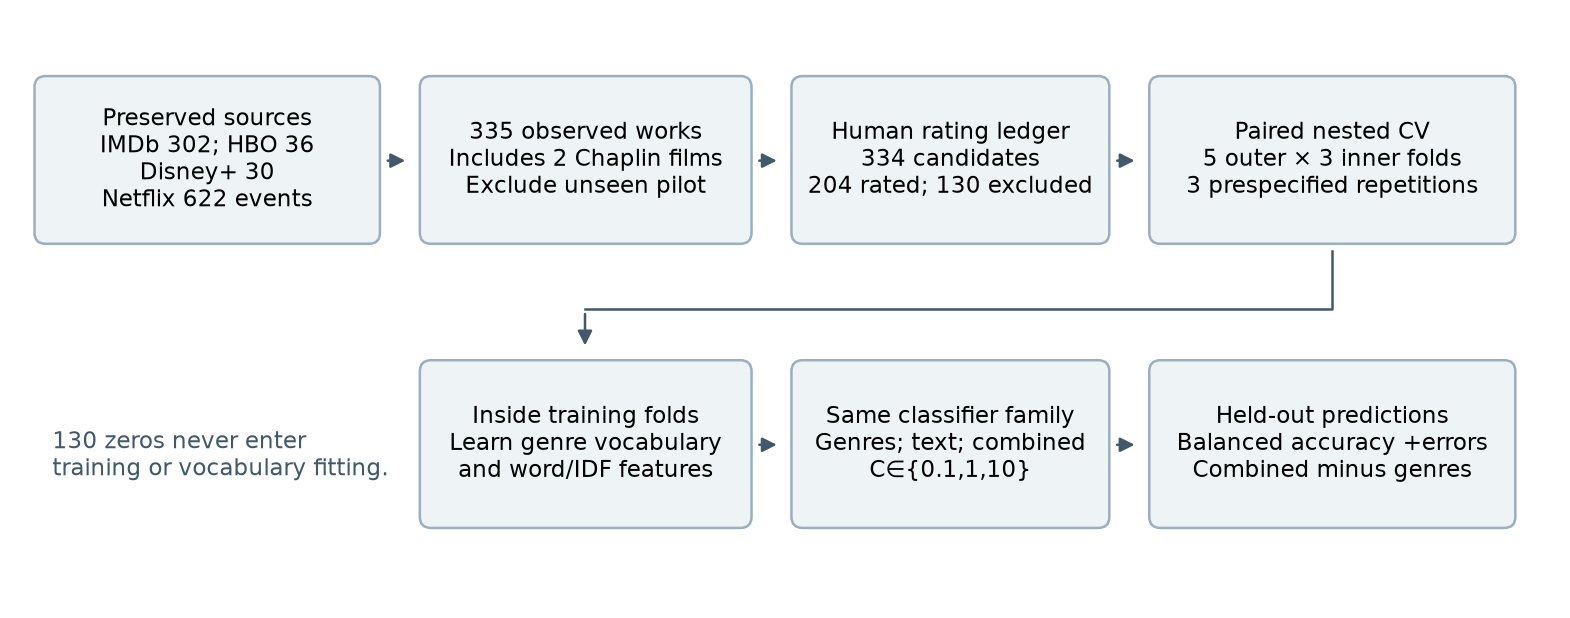

**data profile**

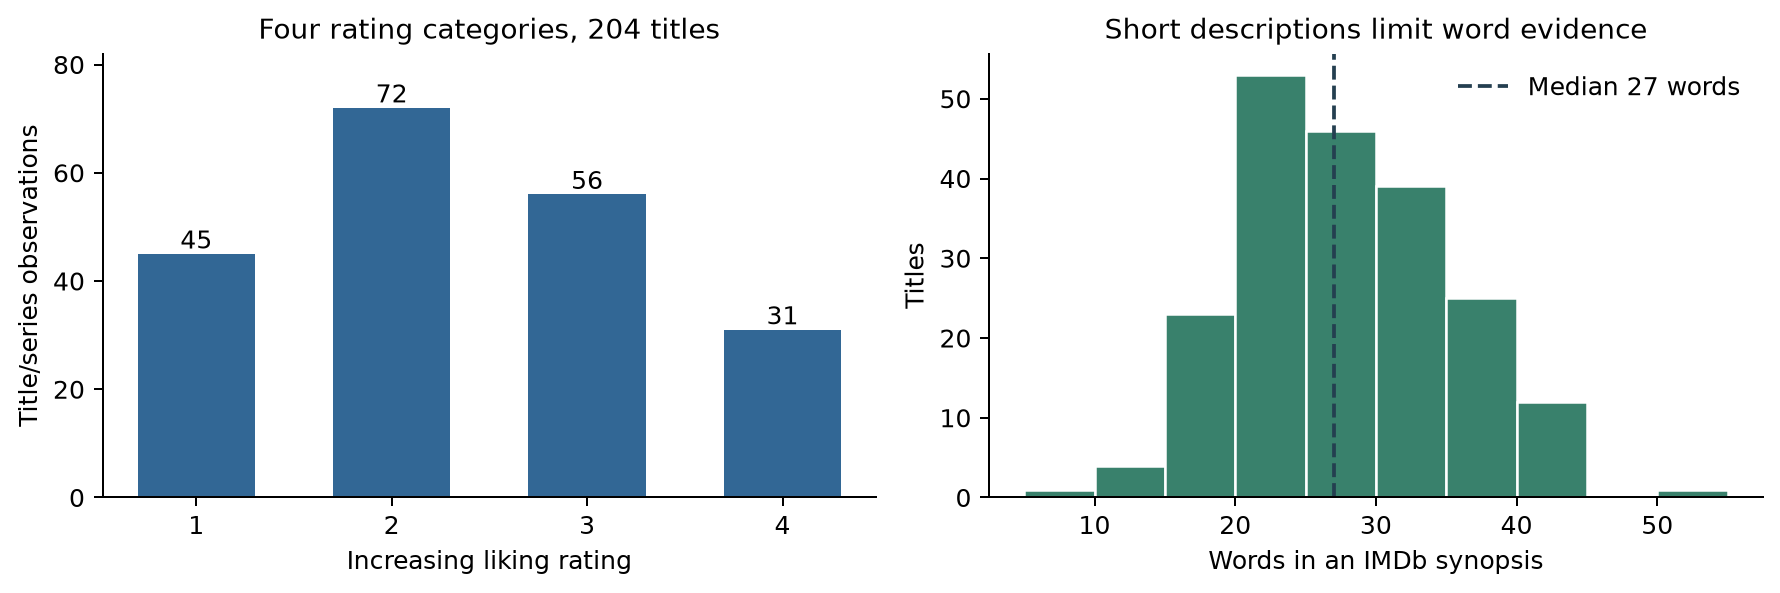

**primary comparison**

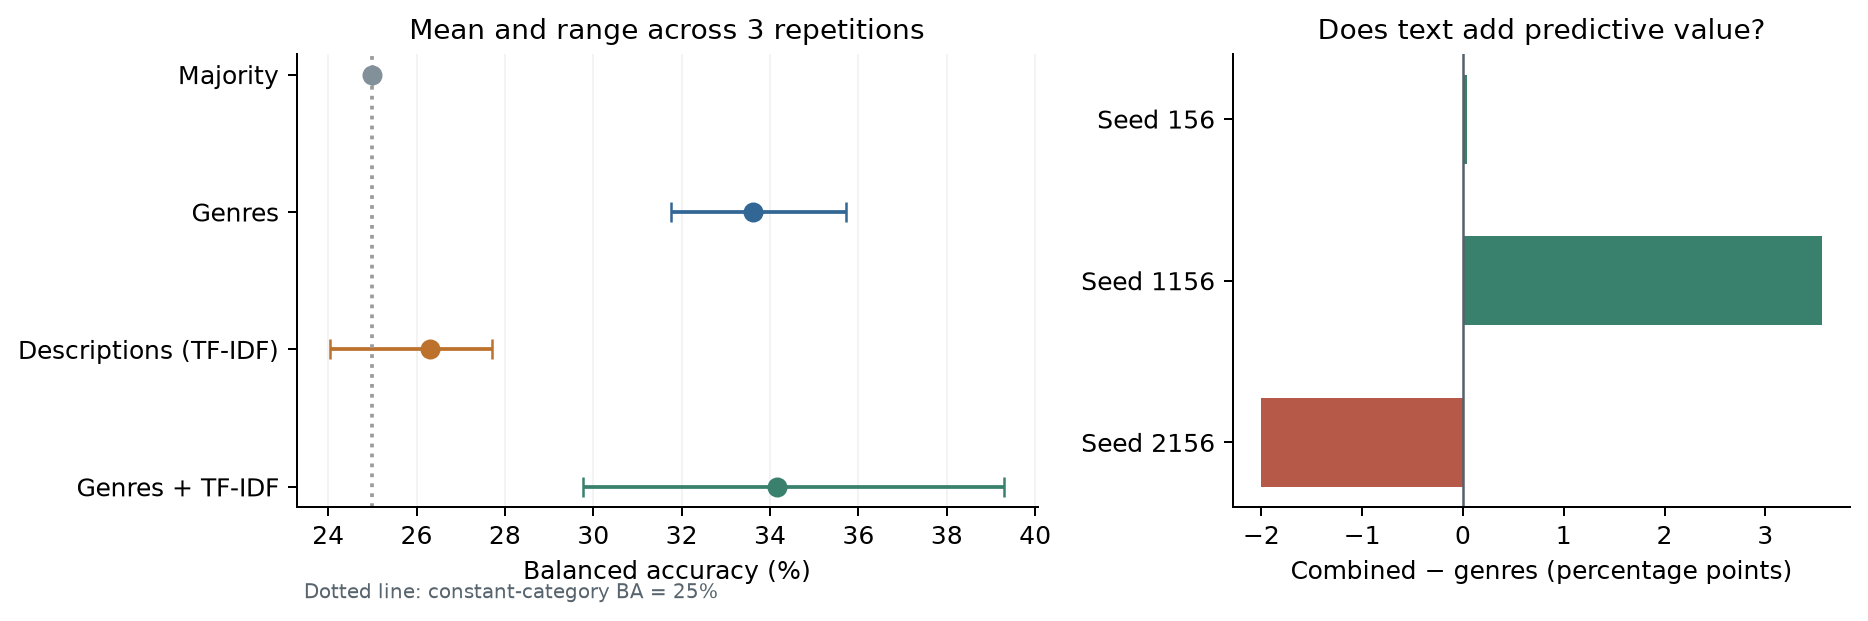

**ordered confusions**

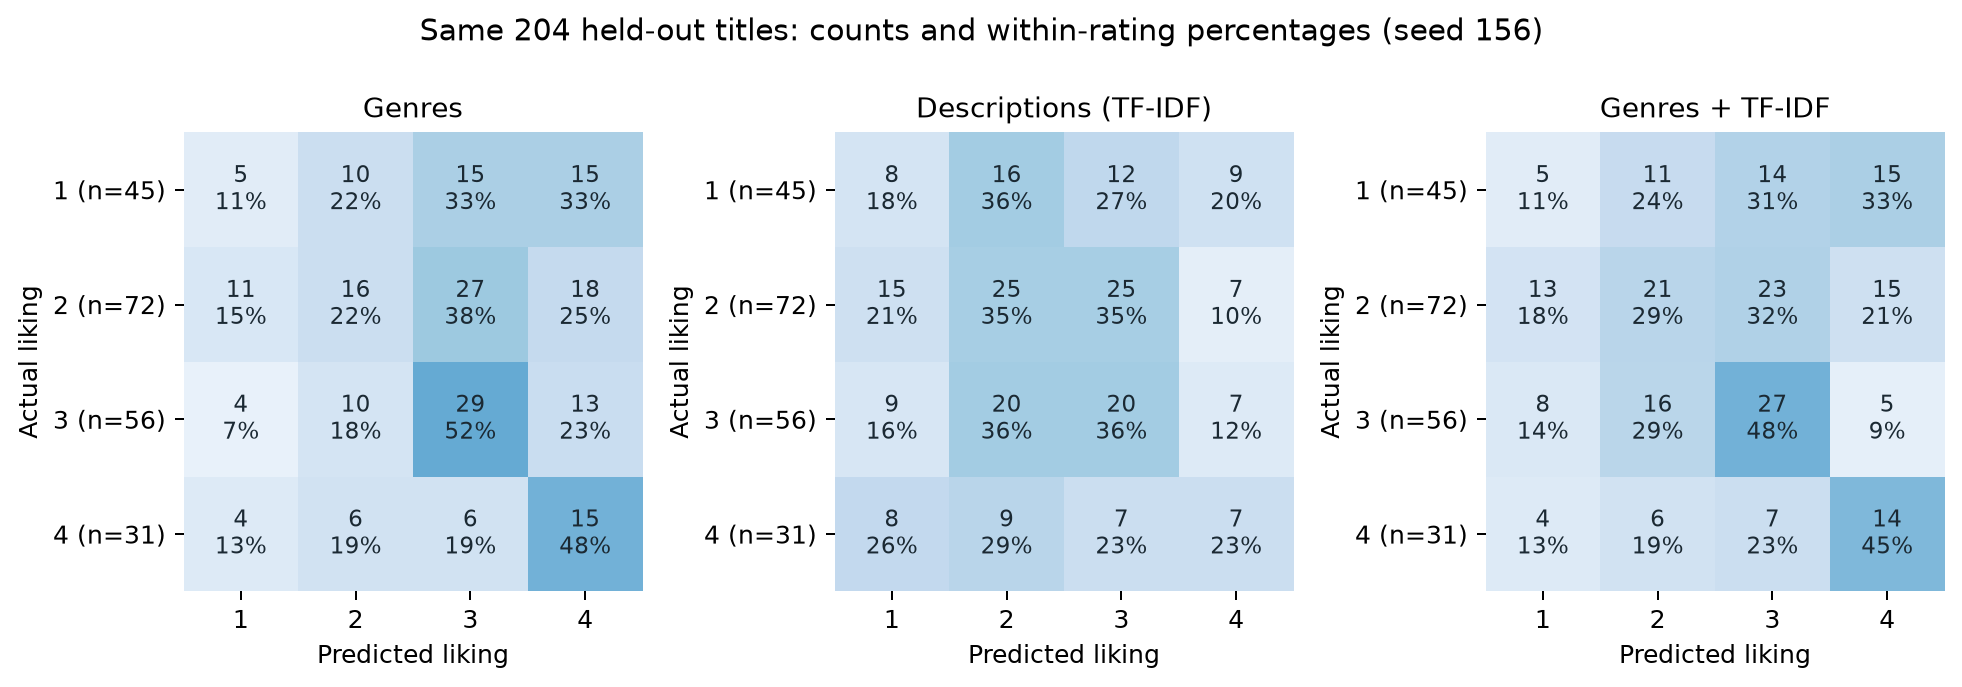

**learning curves**

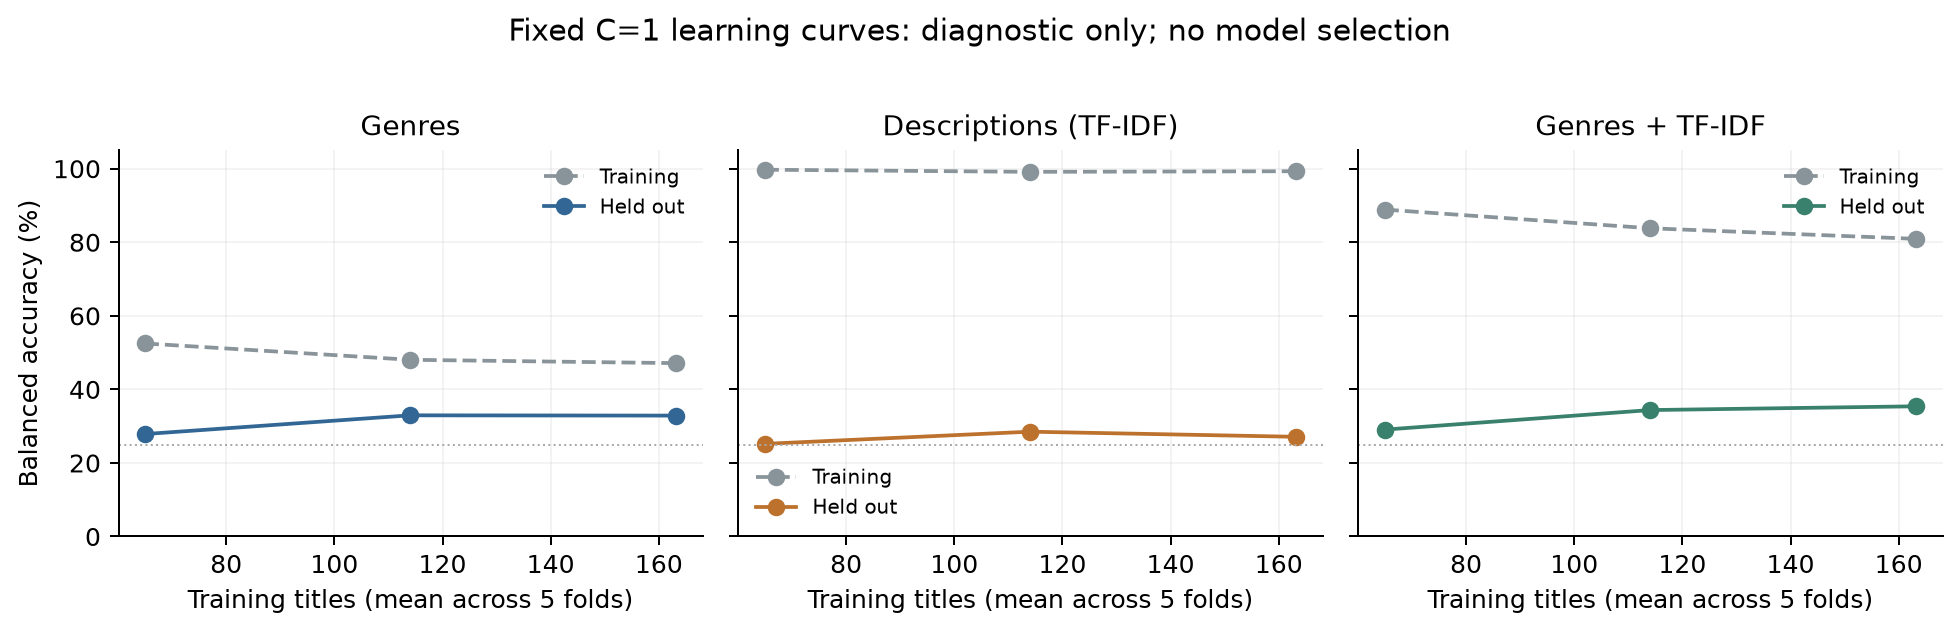

**within genre**

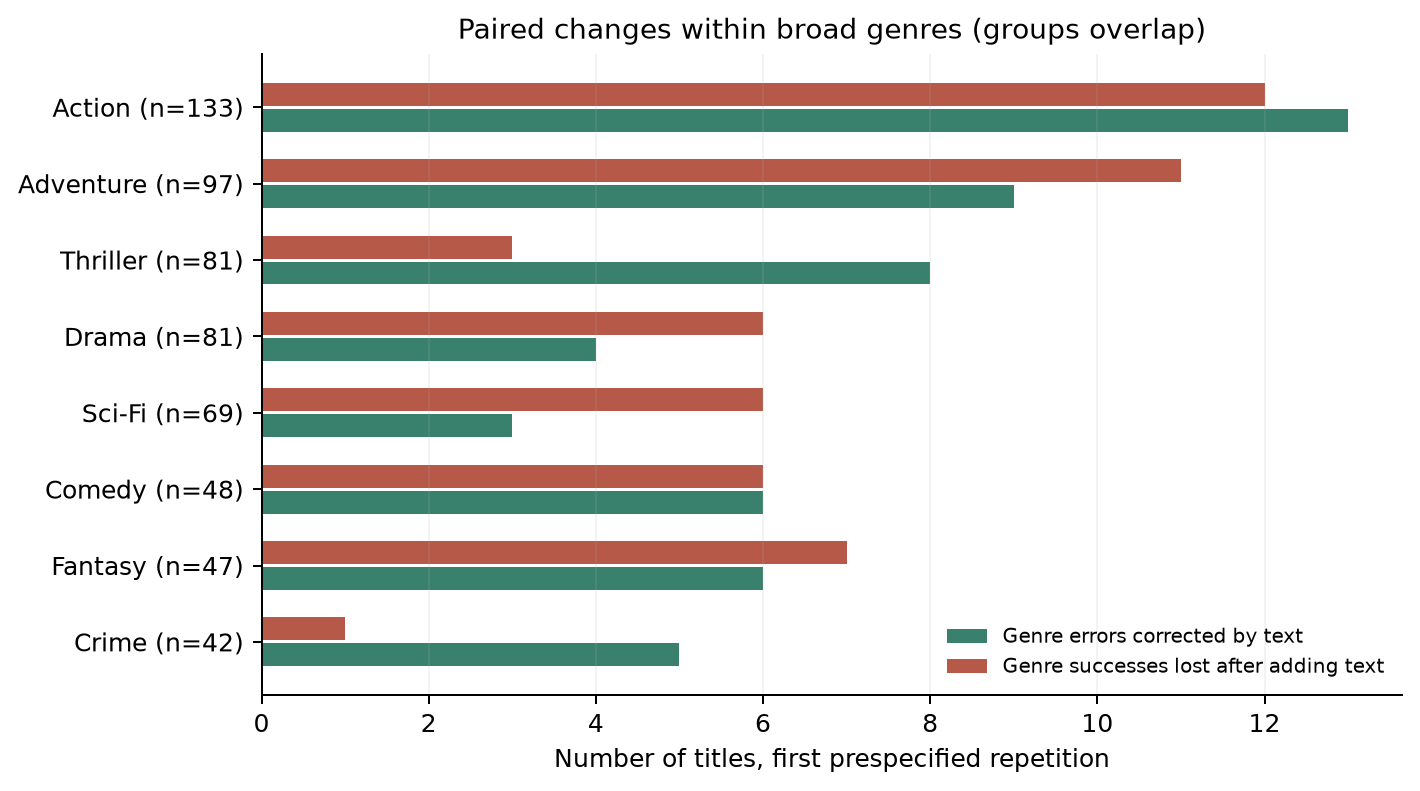

**worked probabilities**

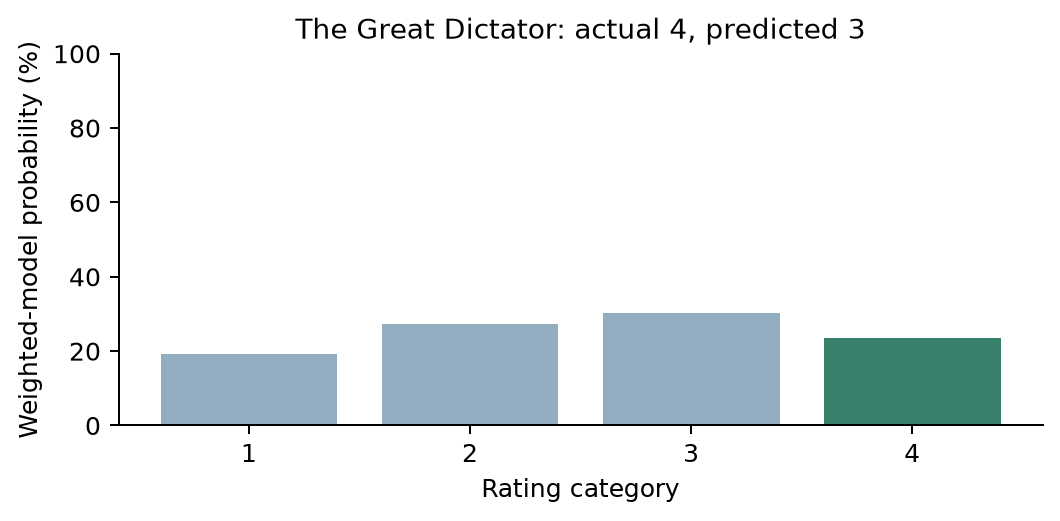

In [15]:
figures = make_figures(result)
assert isinstance(figures, dict) and figures, "Expected a name-to-PNG-path figure mapping."
for name, figure_path in figures.items():
    path = Path(figure_path)
    assert path.is_file() and path.suffix.lower() == ".png"
    display(Markdown(f"**{name.replace('_', ' ')}**"))
    display(Image(filename=str(path)))

### Which titles change when text is added?

The first prespecified seed gives a concrete paired diagnostic: both correct, corrected by text, broken by text, or both wrong. Examples are selected alphabetically within each transition, not by choosing only impressive successes. A correction suggests where the extra representation helped this fitted procedure; it does not identify the causal reason I enjoyed that title.


The table below uses the current 204-title rerun. Corrections and new errors must be interpreted by true category, because balanced accuracy gives each category equal total weight.

In [16]:
errors = pd.read_csv(ROOT / "results/v2/paired_errors.csv", keep_default_na=False)
transition_order = ["both correct", "corrected by text", "broken by text", "both wrong"]
display(errors.transition.value_counts().reindex(transition_order, fill_value=0).rename("titles").to_frame())
examples = errors.sort_values("title").groupby("transition", sort=False).head(3)
display(examples[["transition", "title", "true_rating", "genres_prediction", "combined_prediction"]])
for transition in ["corrected by text", "broken by text"]:
    selected = errors.loc[errors.transition.eq(transition)].sort_values("title").head(1)
    if len(selected):
        row = selected.iloc[0]
        text = data.set_index("record_id").loc[row.record_id, "description_text"]
        display(Markdown(f"**{transition}: {row.title}.** My rating {row.true_rating}; genres predicts {row.genres_prediction}; combined predicts {row.combined_prediction}.\n\n{text}"))

near_extreme = pd.DataFrame(result["summary"]["near_vs_extreme"]).T.rename(index=condition_names)
display(near_extreme.rename_axis("First-seed condition"))

,titles
transition,
both correct,49
corrected by text,18
broken by text,16
both wrong,121


,transition,title,true_rating,genres_prediction,combined_prediction
145,both wrong,13 Reasons Why,1,4,4
95,both wrong,2012,2,3,3
166,both correct,24,3,3,3
80,both correct,6 Underground,3,3,3
129,both correct,Akeelah and the Bee,4,4,4
182,both wrong,All of Us Are Dead,3,2,2
11,corrected by text,Are We There Yet?,1,4,1
195,corrected by text,Bad Boys: Ride or Die,2,1,2
43,corrected by text,Braveheart,3,4,3
82,broken by text,Conan the Barbarian,1,1,2


**corrected by text: Are We There Yet?.** My rating 1; genres predicts 4; combined predicts 1.

To impress a foxy divorcee, ladies' man Nick offers to take her kids on an extended road trip, unaware of the torture he's in for.

**broken by text: Conan the Barbarian.** My rating 1; genres predicts 1; combined predicts 2.

A powerful warrior seeks to avenge the genocide of his people and the murder of his parents at the hands of a snake cult.

,adjacent_errors,two_level_errors,extreme_errors
First-seed condition,,,
Genres + TF-IDF,75,43,19
Genres,77,43,19
Majority,101,31,0
Descriptions (TF-IDF),90,37,17


In [17]:
within_genre = pd.read_csv(ROOT / "results/v2/within_genre.csv")
display(within_genre)
print("Overlapping genres with at least40eligible titles; per-rating counts show sparse categories.")

,genre,n,n_rating1,n_rating2,n_rating3,n_rating4,genre_correct,combined_correct,corrected,broken
0,Action,133,27,52,40,14,43,44,13,12
1,Adventure,97,22,34,31,10,34,32,9,11
2,Comedy,48,16,21,5,6,11,11,6,6
3,Crime,42,10,17,11,4,7,11,5,1
4,Drama,81,16,22,21,22,22,20,4,6
5,Fantasy,47,13,18,7,9,15,14,6,7
6,Sci-Fi,69,15,25,20,9,22,19,3,6
7,Thriller,81,18,28,29,6,23,28,8,3


Overlapping genres with at least40eligible titles; per-rating counts show sparse categories.


### What the inner search actually selected

The outer test labels did not select $C$. The table shows the winning value and actual feature sizes after refitting each outer training set. Vocabulary size can vary because each partition learns its own words. A zero-known-word test description is retained rather than silently removed; its count exposes a limitation of the chosen representation.

The inner score table is tuning evidence, not a second generalization result. Its fold-to-fold variation is descriptive and must not be interpreted as independent uncertainty estimates.

In [18]:
fit_tables = []
search_tables = []
for mode in ["primary", "grouped", "topics"]:
    fit_tables.append(pd.read_csv(ROOT / f"results/v2/{mode}_folds.csv"))
    search_tables.append(pd.read_csv(ROOT / f"results/v2/{mode}_inner_search.csv"))
fits = pd.concat(fit_tables, ignore_index=True)
searches = pd.concat(search_tables, ignore_index=True)
display(fits.loc[fits.condition.ne("majority"), [
    "mode", "seed", "fold", "condition", "C", "features", "text_vocabulary", "zero_text_test_rows", "train_n", "test_n"
]].reset_index(drop=True))
display(searches.groupby(["mode", "condition", "C"]).agg(
    searched_outer_partitions=("fold", "size"), mean_inner_BA=("inner_mean_BA", "mean")
).style.format({"mean_inner_BA": "{:.4f}"}))
print("Complete per-fold inner searches are saved in results/v2/*_inner_search.csv.")

,mode,seed,fold,condition,C,features,text_vocabulary,zero_text_test_rows,train_n,test_n
0,primary,156,0,genres,0.1,17,0,0,163,41
1,primary,156,0,text,1.0,521,521,0,163,41
2,primary,156,0,combined,10.0,538,521,0,163,41
3,primary,156,1,genres,1.0,17,0,0,163,41
4,primary,156,1,text,1.0,520,520,0,163,41
...,...,...,...,...,...,...,...,...,...,...
65,topics,156,2,genre_topics,10.0,21,0,0,163,41
66,topics,156,3,topics,1.0,5,0,0,163,41
67,topics,156,3,genre_topics,10.0,22,0,0,163,41
68,topics,156,4,topics,1.0,5,0,0,164,40


Complete per-fold inner searches are saved in results/v2/*_inner_search.csv.


## A held-out mathematical example: *The Great Dictator*

This example was fixed from my personal opening before scores were inspected. The saved artifact comes from the first repetition's combined model, in the fold where the film was held out. It is therefore an explanation of a held-out prediction, not a training-fit success selected afterwards.

For predicted category $a$ and comparison category $b$,

\[
z_a-z_b=(b_a-b_b)+\sum_j x_j(w_{a,j}-w_{b,j}).
\]

Each row below contributes to this **logit difference**. A positive contribution favors $a$ over $b$; it does not mean that the word inherently improves enjoyment. Contributions depend on the fitted coefficients, the normalized representation, the other category and this training sample. They are associations within the model, not causal explanations of my preferences.


The output below records the actual current prediction, probabilities and surviving features. A correct argmax alone would not show story understanding; the margin and contributing words explain what the fitted representation actually used.

In [19]:
worked = read_json("results/v2/worked_example.json")
assert worked["held_out"] and worked["record_id"] == protocol["worked_example_id"]
display(Markdown(
    f"**{worked['title']}**: my label **{worked['true_rating']}**, predicted label **{worked['predicted_rating']}**, "
    f"comparison category **{worked['contrast_rating']}**. Fold {worked['fold'] + 1}, seed {worked['seed']}.\n\n"
    f"Genres: {worked['genres']}.\n\n{worked['description']}"
))
class_order = sorted(worked["scores"], key=int)
score_vector = np.array([worked["scores"][key] for key in class_order])
saved_probabilities = np.array([worked["probabilities"][key] for key in class_order])
np.testing.assert_allclose(softmax(score_vector[None, :])[0], saved_probabilities)
display(pd.DataFrame({"category": class_order, "linear_score": score_vector,
                      "softmax_probability": saved_probabilities}).style.format({"linear_score": "{:.4f}", "softmax_probability": "{:.4f}"}))
terms = pd.DataFrame(worked["nonzero_terms"])
display(terms.head(12).style.format({"x": "{:.4f}", "coefficient_difference": "{:+.4f}", "contribution": "{:+.4f}"}))
calculated_margin = worked["intercept_difference"] + terms.contribution.sum()
saved_margin = worked["scores"][str(worked["predicted_rating"])] - worked["scores"][str(worked["contrast_rating"])]
np.testing.assert_allclose(calculated_margin, saved_margin)
display(pd.DataFrame({"quantity": ["Intercept difference", "Sum of all feature contributions", "Reconstructed score difference", "Saved score difference"],
                      "value": [worked["intercept_difference"], terms.contribution.sum(), calculated_margin, saved_margin]}))
print("Softmax probabilities sum to", round(saved_probabilities.sum(), 12))
print("Outer-training vocabulary:", worked["text_vocabulary_size"], "words; total features:", worked["feature_count"])

**The Great Dictator**: my label **4**, predicted label **3**, comparison category **4**. Fold 2, seed 156.

Genres: Comedy, Drama, War.

Dictator Adenoid Hynkel tries to expand his empire while a poor Jewish barber tries to avoid persecution from Hynkel's regime.

,category,linear_score,softmax_probability
0,1,-0.2550,0.1910
1,2,0.0981,0.2718
2,3,0.2026,0.3018
3,4,-0.0456,0.2355


,feature,x,coefficient_difference,contribution
0,genres__War,0.4082,+3.3349,+1.3614
1,genres__Drama,0.4082,-1.7221,-0.7030
2,text__from,0.2954,-1.7569,-0.5190
3,text__his,0.2388,+1.3892,+0.3317
4,text__to,0.3249,+0.8106,+0.2634
5,genres__Comedy,0.4082,-0.3518,-0.1436
6,text__while,0.5001,-0.0999,-0.0500


,quantity,value
0,Intercept difference,-0.292822
1,Sum of all feature contributions,0.540931
2,Reconstructed score difference,0.248109
3,Saved score difference,0.248109


Softmax probabilities sum to 1.0
Outer-training vocabulary: 520 words; total features: 537


## What the topic model describes, and what it does not

The predictive LDA results above fitted counts, topics and classifier only inside training folds. The table below is different: an **all-eligible-data descriptive topic fit after evaluation**, used to inspect recurring words. It has no held-out prediction score. Naming a topic from its top words is a human interpretation, and topic coherence does not demonstrate preference prediction. This table cannot justify retroactively choosing a topic count or changing the main procedure.

In [20]:
display(pd.read_csv(ROOT / "results/v2/lda_topics_descriptive.csv"))

,topic,top_words
0,1,"group, father, sets, man, future, mysterious, family, life"
1,2,"life, young, james, bond, world, school, american, family"
2,3,"world, young, lives, new, time, agent, family, power"
3,4,"new, dangerous, mission, bond, team, friend, group, secret"
4,5,"earth, john, world, war, time, powerful, planet, death"


## A fixed-procedure learning-curve diagnostic

The learning curves vary training-set size while fixing $C=1$, using the first prespecified outer split and the same preprocessing rules. They are not another inner search and are not the tuned main procedure. Training-versus-validation differences can suggest sensitivity to data quantity, but a curve cannot by itself prove that more data or another model would solve the problem. No setting is changed from these curves after observing the outer results.

The smaller stratified training subsets were sampled separately at each fraction; they are **not nested sets of titles**. In addition, fixing \(C\) does not hold the effective regularization-versus-data balance constant as sample size changes. The curves combine sample size, subset composition, learned vocabulary and the fixed classifier convention. They diagnose that complete procedure rather than isolate the effect of adding a particular group of movies.

In [21]:
curve = result["learning_curves"]
curve_summary = curve.groupby(["condition", "fraction"]).agg(
    mean_training_titles=("n", "mean"), training_BA=("train_BA", "mean"), validation_BA=("validation_BA", "mean")
).reset_index()
show_percent(curve_summary, ["training_BA", "validation_BA"])

,condition,fraction,mean_training_titles,training_BA,validation_BA
0,combined,0.400000,65.000000,88.88,29.06
1,combined,0.700000,114.000000,83.81,34.37
2,combined,1.000000,163.200000,80.92,35.40
3,genres,0.400000,65.000000,52.49,27.86
4,genres,0.700000,114.000000,48.05,32.94
5,genres,1.000000,163.200000,47.13,32.87
6,text,0.400000,65.000000,99.72,25.19
7,text,0.700000,114.000000,99.14,28.50
8,text,1.000000,163.200000,99.31,27.11


## Scope, limitations and the next pipeline

The result describes one viewer's selected and recalled viewing history, not all viewers or the full streaming catalogue. I chose what to save and watch, so the sample is selective. A series rating compresses reactions across episodes and may reflect substantial partial viewing. A short synopsis omits acting, pacing, visuals, timing and my viewing context. My current mood is absent from the measurements.

Related titles can share names and story language even after episode consolidation. The grouped sensitivity check helps assess one form of dependence, but its conservative map is incomplete and its folds differ from the ordinary-title target. Repeated CV still uses the same 204 titles; small gains can rest on a few predictions. Inner selection separates tuning from outer evaluation but cannot manufacture more preference evidence.

The controlled representation comparison gives a small+0.53 pp mean gain, with a sign change across seeds. Family selection and grouped results below condition that conclusion further; no dependable mood-sensitive recommender has been established.

The next useful step is to collect more independent ratings with stable category anchors and notes on the desired mood and whether the title delivered it. I also want to test longer plot summaries and explicit adaptation information, such as whether a title is based on a book, because short blurbs may omit signals relevant to my taste.

Alongside ordinal prediction, I will compare TF-IDF with embeddings from a pretrained neural network: numerical text representations intended to place similar meanings close together. These could support semantic searches for a desired mood and serve as classifier inputs. I would compare short and longer descriptions using the same representation first, then compare representations on the same text, so any gain can be traced to more complete information or a different way of representing it. A newly fixed evaluation plan would test whether these changes improve held-out classification, rather than assuming that longer text or a neural model must help.

**AI assistance:** AI supported source collection, cleaning and identity checks, implementation, mathematical explanation, figures and drafting. James supplied the personal ratings, research motivation, corrections and review. Preserved raw files, immutable hashes, recorded exclusions, frozen partitions and executed outputs make that assistance inspectable. AI-generated explanations do not replace checking source evidence or measured results.

## Primary references

- [scikit-learn: TF-IDF weighting and feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting).
- [scikit-learn: multinomial logistic regression and regularization](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
- [scikit-learn: balanced accuracy](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html).
- [scikit-learn: cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) and [nested versus non-nested evaluation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).
- [scikit-learn: avoiding data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
- [Blei, Ng and Jordan (2003): Latent Dirichlet Allocation](https://www.jmlr.org/papers/volume3/blei03a/blei03a.pdf) and [official count-based LDA example](https://scikit-learn.org/stable/auto_examples/applications/plot_topics_extraction_with_nmf_lda.html).
- [Bates, Hastie and Tibshirani: what cross-validation estimates and its uncertainty](https://arxiv.org/abs/2104.00673).
- [IMDb Genres](https://help.imdb.com/article/contribution/titles/genres/GZDRMS6R742JRGAG), [Interests](https://help.imdb.com/article/contribution/titles/interests/G4Q8HQTQJ6YZ7H7B), and [list-item descriptions](https://help.imdb.com/article/imdb/track-movies-tv/faq-for-the-list-feature/GNQMN47VZSE7KW38).

## Classifier selection and validation strategy
The genre-only and combined feature conditions each compare four classifier families, three settings each. Logistic regression now uses the explicit weighted cross-entropy/gradient implementation above; SVM, Complement NB and the bounded tree use library estimators. The manual optimizer check establishes what agrees with the library implementation, not predictive superiority.

This v2 protocol was frozen before its fits, after earlier results on 203 ratings were known. It remains exploratory. Twelve configurations per condition/selector receive the same partitions. No test score selects a family or parameter.

In [2]:
from sklearn.base import clone
from src.manual_models import ManualSoftmaxClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import balanced_accuracy_score
from sklearn.exceptions import ConvergenceWarning
import warnings
from src.experiments_v2 import make_pipeline, load_data
from src.selection_study_v2 import (
    freeze_selection, indices, serial_params, save_results,
    OUT, FAMILIES,
)

# Each classifier is inside the same fold-fitted feature pipeline.
parameter_grid = [
    {"classifier": [ManualSoftmaxClassifier(class_weight="balanced", max_iter=2000)],
     "classifier__C": [0.1, 1.0, 10.0]},
    {"classifier": [LinearSVC(class_weight="balanced", dual="auto",
        max_iter=10000, random_state=156)],
     "classifier__C": [0.1, 1.0, 10.0]},
    {"classifier": [ComplementNB(norm=False, force_alpha=True)],
     "classifier__alpha": [10.0, 1.0, 0.1]},
    {"classifier": [DecisionTreeClassifier(class_weight="balanced",
        min_samples_leaf=5, random_state=156)],
     "classifier__max_depth": [2, 4, 8]},
]
study_data = load_data()
study_protocol = freeze_selection(study_data, parameter_grid)
display(pd.DataFrame(study_protocol["candidate_parameters"]))
display(pd.DataFrame([{"seed": p["seed"], **p["counts"]}
                      for p in study_protocol["plans"]]))

,classifier,classifier__C,classifier__alpha,classifier__max_depth
0,ManualSoftmaxClassifier(),0.1,NaN,NaN
1,ManualSoftmaxClassifier(),1.0,NaN,NaN
2,ManualSoftmaxClassifier(),10.0,NaN,NaN
3,"LinearSVC(class_weight='balanced', max_iter=10...",0.1,NaN,NaN
4,"LinearSVC(class_weight='balanced', max_iter=10...",1.0,NaN,NaN
5,"LinearSVC(class_weight='balanced', max_iter=10...",10.0,NaN,NaN
6,ComplementNB(),NaN,10.0,NaN
7,ComplementNB(),NaN,1.0,NaN
8,ComplementNB(),NaN,0.1,NaN
9,DecisionTreeClassifier(class_weight='balanced'...,NaN,NaN,2.0


,seed,development,test,single_train,single_validation
0,156,"{'1': 36, '2': 57, '3': 45, '4': 25}","{'1': 9, '2': 15, '3': 11, '4': 6}","{'1': 29, '2': 45, '3': 36, '4': 20}","{'1': 7, '2': 12, '3': 9, '4': 5}"
1,1156,"{'1': 36, '2': 57, '3': 45, '4': 25}","{'1': 9, '2': 15, '3': 11, '4': 6}","{'1': 29, '2': 45, '3': 36, '4': 20}","{'1': 7, '2': 12, '3': 9, '4': 5}"
2,2156,"{'1': 36, '2': 57, '3': 45, '4': 25}","{'1': 9, '2': 15, '3': 11, '4': 6}","{'1': 29, '2': 45, '3': 36, '4': 20}","{'1': 7, '2': 12, '3': 9, '4': 5}"


### Development selection, then common-test assessment
Each seed assigns 163 titles to development and 41 to test. Five-fold selection trains each candidate on 130–131 titles, validating 32–33; the single split trains 130 and validates 33. Both strategies refit each family finalist on all 163 before the same test. Cached 130-title fits isolate the practical cost of leaving validation titles unused after selection. Selection uses development BA only; the code saves all choices before scoring test predictions. Across 3 seeds×2 featureconditions, this makes 480 fits.

In [3]:
warnings.filterwarnings("error", category=ConvergenceWarning)
X = study_data[["genres", "description_text"]]
y = study_data.rating.to_numpy()
candidate_settings = list(ParameterGrid(parameter_grid))
families = [type(p["classifier"]).__name__ for p in candidate_settings]
search_rows, choice_rows, pending_predictions = [], [], []
fit_count = 0

for plan in study_protocol["plans"]:
    dev, test, inner_splits, train, validation = indices(study_data, plan)
    X_dev, y_dev = X.iloc[dev], y[dev]
    for condition in study_protocol["conditions"]:
        candidate_pipeline = make_pipeline(condition)
        # CV selects settings; refit=False lets us refit all four finalists.
        search = GridSearchCV(
            candidate_pipeline, parameter_grid,
            scoring="balanced_accuracy", cv=inner_splits,
            refit=False, n_jobs=1, error_score="raise",
        )
        search.fit(X_dev, y_dev)
        fit_count += 12 * 5
        cv_scores = search.cv_results_["mean_test_score"]
        single_models, single_scores = [], []
        for params in candidate_settings:
            fitted = clone(candidate_pipeline).set_params(**clone(params, safe=False))
            fitted.fit(X_dev.iloc[train], y_dev[train])
            single_models.append(fitted)
            single_scores.append(balanced_accuracy_score(
                y_dev[validation], fitted.predict(X_dev.iloc[validation])))
            fit_count += 1

        for strategy, validation_scores in [("cv", cv_scores), ("single", single_scores)]:
            # First maximum implements the frozen family/parameter tie rules.
            winner = max(range(12), key=lambda j: validation_scores[j])
            for j, params in enumerate(candidate_settings):
                search_rows.append(dict(seed=plan["seed"], condition=condition,
                    strategy=strategy, candidate=j, family=families[j],
                    parameters=json.dumps(serial_params(params), sort_keys=True),
                    development_BA=float(validation_scores[j])))
            for family in FAMILIES:
                candidates = [j for j in range(12) if families[j] == family]
                best = max(candidates, key=lambda j: validation_scores[j])
                params = candidate_settings[best]
                setting = {k.replace("classifier__", ""):v
                           for k,v in params.items() if k != "classifier"}
                choice_rows.append(dict(seed=plan["seed"], condition=condition,
                    strategy=strategy, family=family, candidate=best,
                    setting=json.dumps(setting), development_BA=float(validation_scores[best]),
                    selected=(best == winner)))
                selected = clone(candidate_pipeline).set_params(**clone(params, safe=False))
                selected.fit(X_dev, y_dev)
                fit_count += 1
                models = [(strategy + "_refit", selected, len(dev))]
                if strategy == "single":
                    models.append(("single_no_refit", single_models[best], len(train)))
                for label, model, n_train in models:
                    predicted = model.predict(X.iloc[test])
                    pending_predictions.append(dict(seed=plan["seed"],
                        condition=condition, strategy=label, family=family,
                        setting=json.dumps(setting), selected=(best == winner),
                        n_train=n_train, record_ids=study_data.record_id.iloc[test].tolist(),
                        predicted=predicted.tolist()))
        print(f"Finished seed {plan['seed']}, {condition}; {fit_count} fits", flush=True)

# Persist every development choice BEFORE evaluating any test predictions.
OUT.mkdir(parents=True, exist_ok=True)
pd.DataFrame(choice_rows).to_csv(OUT / "choices_before_test.csv", index=False)
prediction_rows = []
truth_by_id = study_data.set_index("record_id").rating.to_dict()
for batch in pending_predictions:
    metadata = {k:v for k,v in batch.items() if k not in {"record_ids", "predicted"}}
    for record_id, prediction in zip(batch["record_ids"], batch["predicted"]):
        prediction_rows.append(dict(**metadata, record_id=record_id,
            true=truth_by_id[record_id], prediction=prediction))
study_searches, study_choices, study_predictions, study_scores, study_paired = save_results(
    study_data, study_protocol, search_rows, choice_rows, prediction_rows, fit_count)
display(study_choices.loc[study_choices.selected].reset_index(drop=True))
display(study_scores)
display(study_paired * 100)

Finished seed 156, genres; 80 fits


Finished seed 156, combined; 160 fits


Finished seed 1156, genres; 240 fits


Finished seed 1156, combined; 320 fits


Finished seed 2156, genres; 400 fits


Finished seed 2156, combined; 480 fits


,seed,condition,strategy,family,candidate,setting,development_BA,selected
0,156,genres,cv,ManualSoftmaxClassifier,1,"{""C"": 1.0}",0.351362,True
1,156,genres,single,DecisionTreeClassifier,10,"{""max_depth"": 4}",0.209722,True
2,156,combined,cv,ManualSoftmaxClassifier,2,"{""C"": 10.0}",0.344506,True
3,156,combined,single,LinearSVC,5,"{""C"": 10.0}",0.266270,True
4,1156,genres,cv,ManualSoftmaxClassifier,1,"{""C"": 1.0}",0.379899,True
5,1156,genres,single,ManualSoftmaxClassifier,1,"{""C"": 1.0}",0.457540,True
6,1156,combined,cv,ManualSoftmaxClassifier,0,"{""C"": 0.1}",0.331540,True
7,1156,combined,single,ManualSoftmaxClassifier,0,"{""C"": 0.1}",0.388095,True
8,2156,genres,cv,ManualSoftmaxClassifier,0,"{""C"": 0.1}",0.363905,True
9,2156,genres,single,DecisionTreeClassifier,10,"{""max_depth"": 4}",0.390079,True


,seed,condition,strategy,family,BA,selected,n_train,n_test,setting
0,156,genres,cv_refit,ManualSoftmaxClassifier,0.367677,True,163,41,"{""C"": 1.0}"
1,156,genres,cv_refit,LinearSVC,0.415909,False,163,41,"{""C"": 10.0}"
2,156,genres,cv_refit,ComplementNB,0.413636,False,163,41,"{""alpha"": 10.0}"
3,156,genres,cv_refit,DecisionTreeClassifier,0.345455,False,163,41,"{""max_depth"": 2}"
4,156,genres,single_refit,ManualSoftmaxClassifier,0.391414,False,163,41,"{""C"": 0.1}"
...,...,...,...,...,...,...,...,...,...
67,2156,combined,single_no_refit,LinearSVC,0.318182,False,130,41,"{""C"": 0.1}"
68,2156,combined,single_refit,ComplementNB,0.233333,False,163,41,"{""alpha"": 10.0}"
69,2156,combined,single_no_refit,ComplementNB,0.216667,False,130,41,"{""alpha"": 10.0}"
70,2156,combined,single_refit,DecisionTreeClassifier,0.308333,False,163,41,"{""max_depth"": 2}"


condition              combined     genres  combined_minus_genres
seed strategy                                                    
156  cv_refit         38.989899  36.767677               2.222222
     single_no_refit  30.707071  34.873737              -4.166667
     single_refit     37.146465  25.656566              11.489899
1156 cv_refit         34.015152  31.515152               2.500000
     single_no_refit  36.742424  29.242424               7.500000
     single_refit     34.015152  31.515152               2.500000
2156 cv_refit         30.984848  29.318182               1.666667
     single_no_refit  34.040404  44.747475             -10.707071
     single_refit     29.090909  30.126263              -1.035354

### Compare outcomes without selecting from tests
Dots show common-test scores of development-tuned family finalists. The strategy plot follows the overall development-selected winner, even when another family scores better on test. Final training budgets are matched at 163 for the first two strategies; the 130-title cache is a separate diagnostic. Test partitions overlap across seeds, so ranges are descriptive. These 41-title scores must not be directly ranked against pooled 204-title nested-CV scores as if only the evaluation method changed.

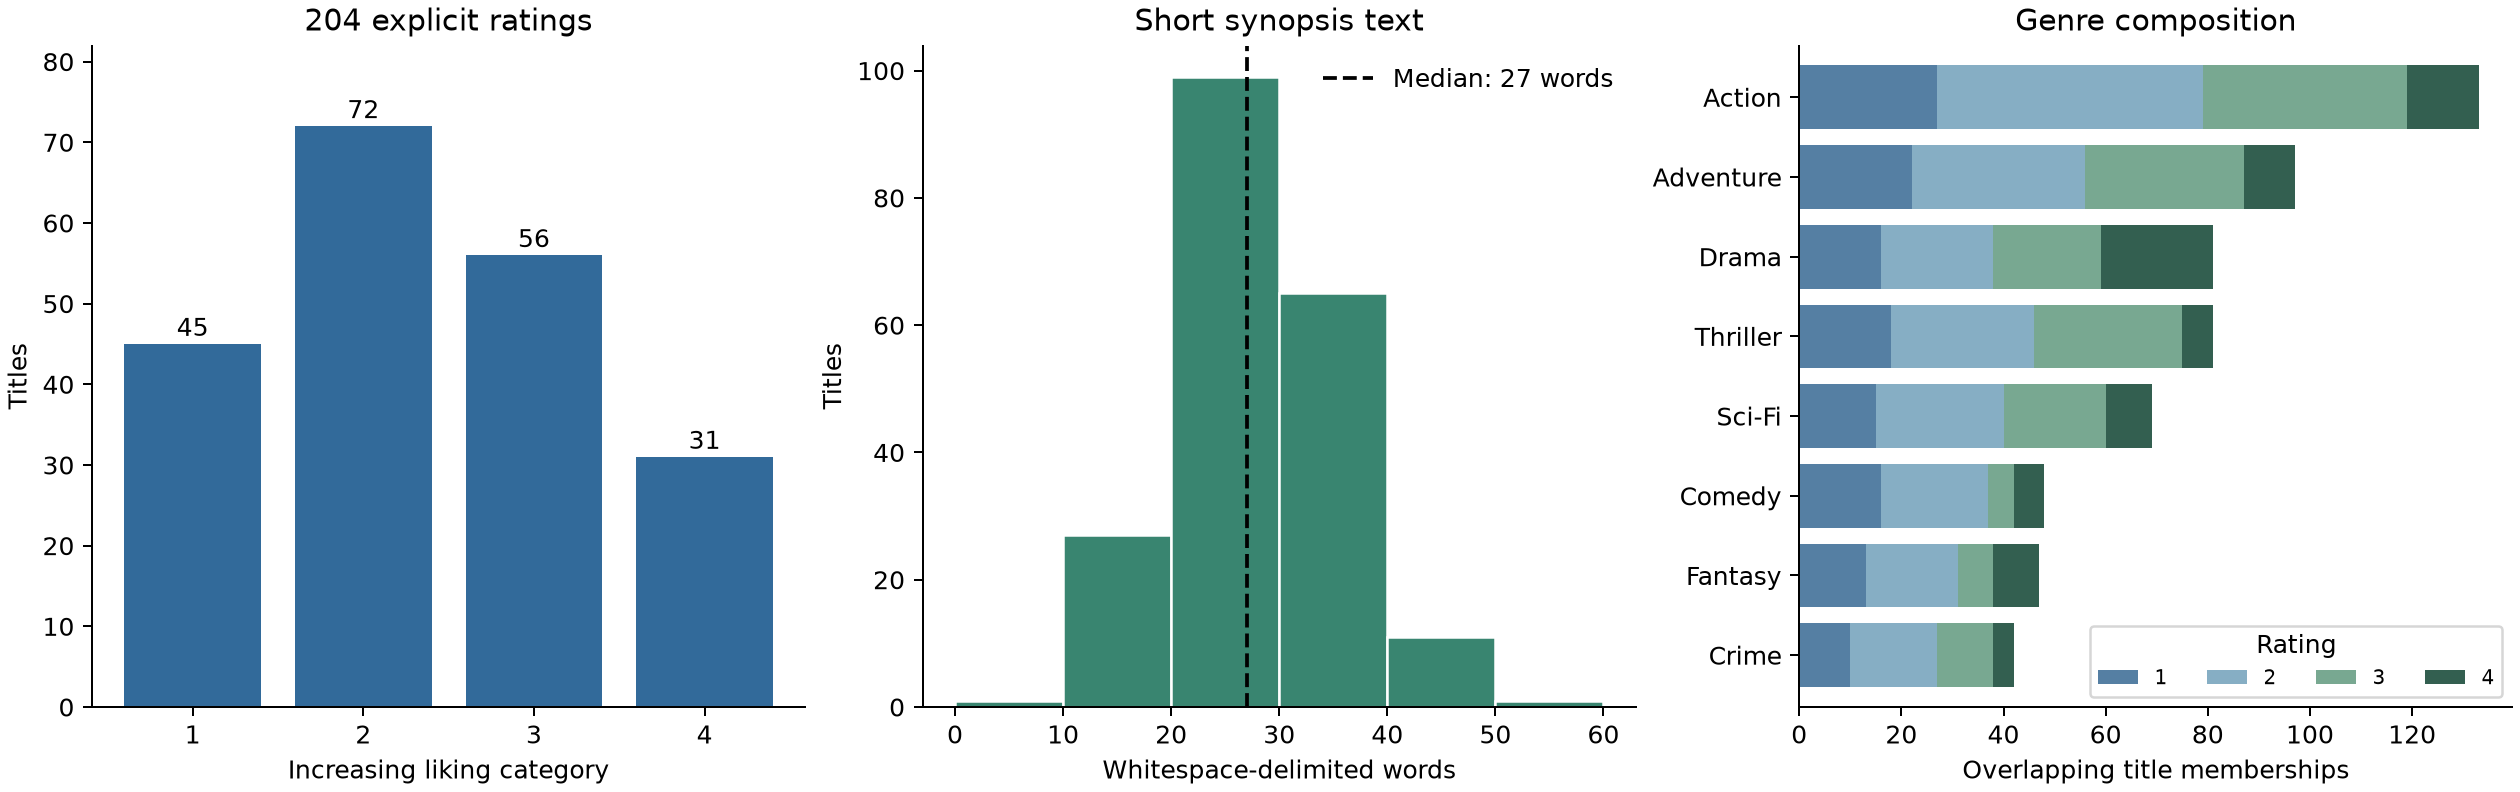

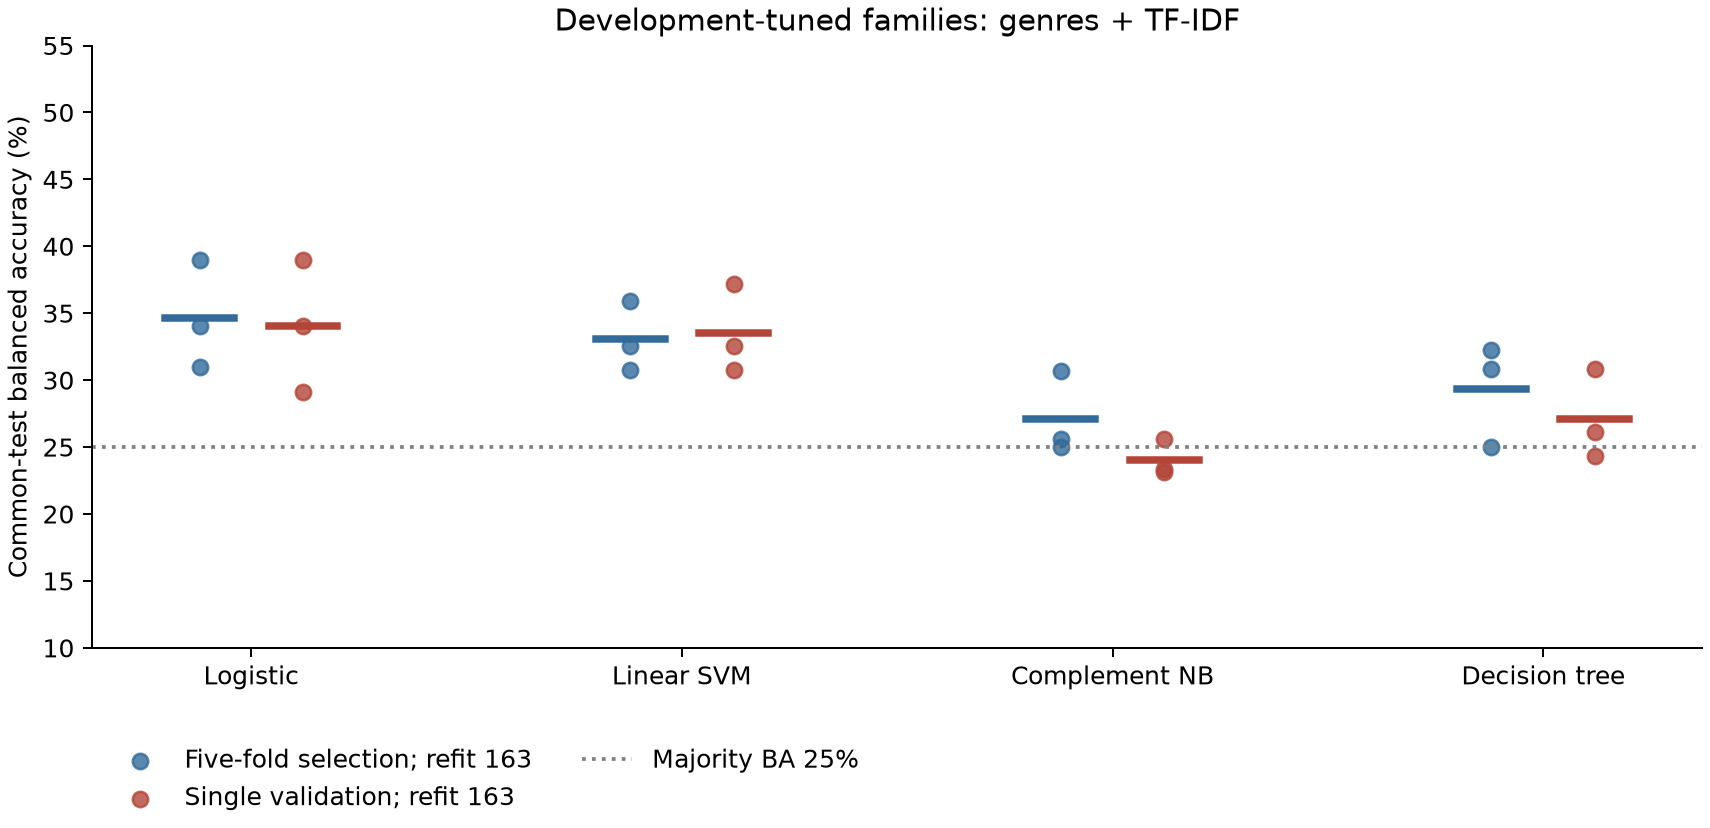

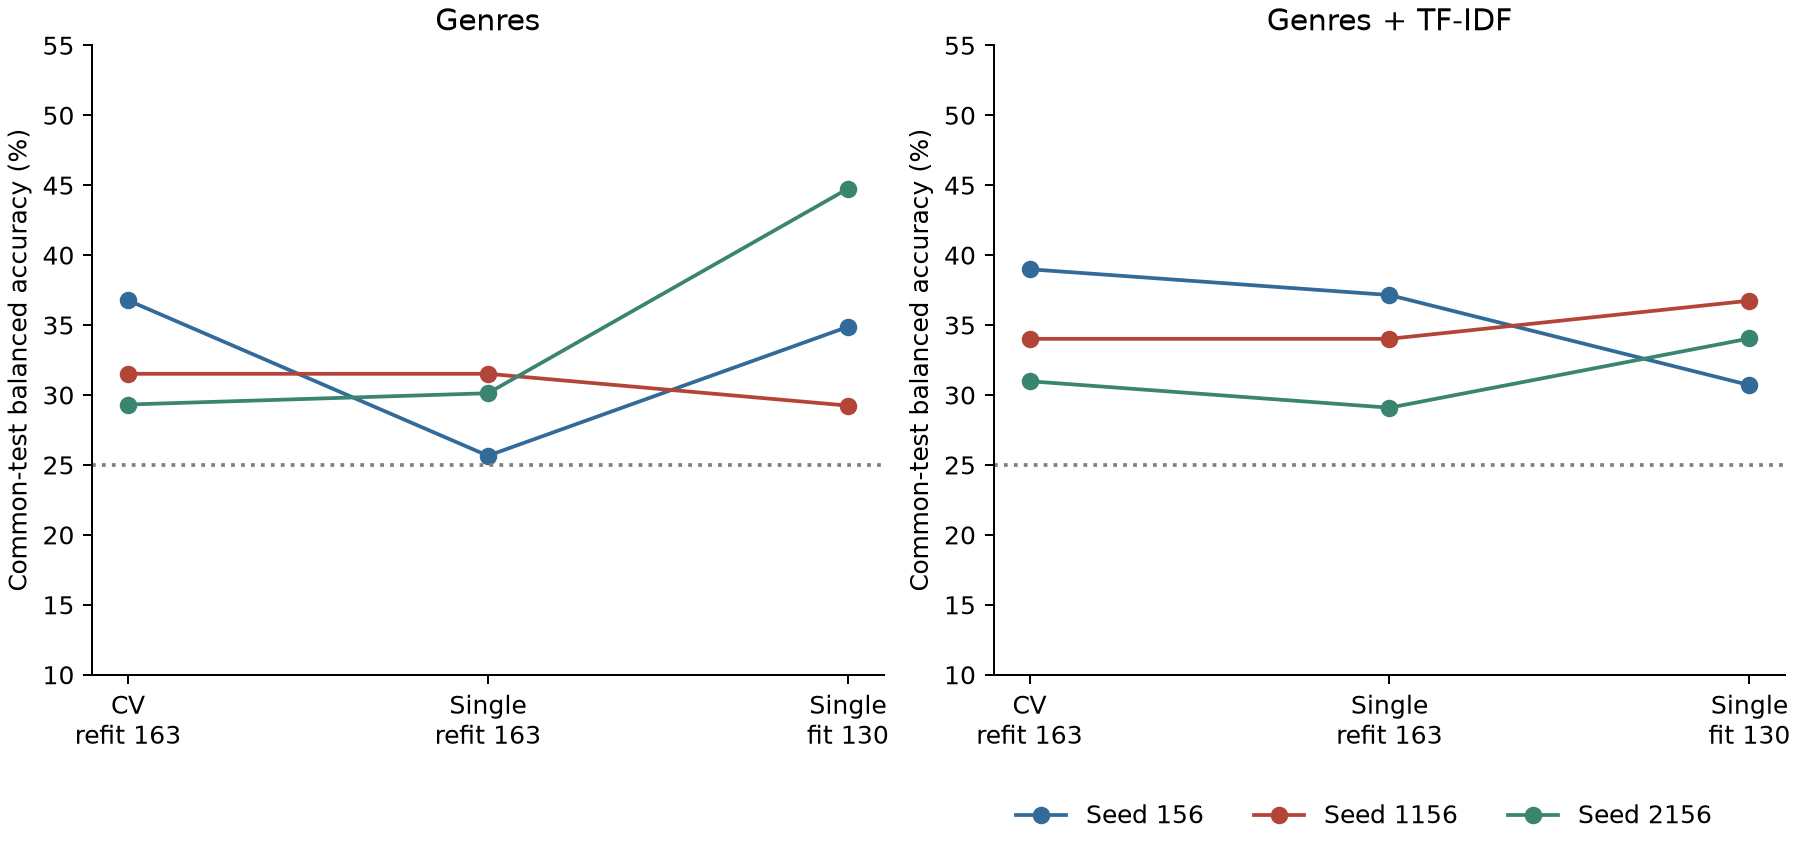

mean    min    max
condition strategy     family                                      
combined  cv_refit     ComplementNB             27.10  25.00  30.71
                       DecisionTreeClassifier   29.35  25.00  32.22
                       LinearSVC                33.09  30.76  35.93
                       ManualSoftmaxClassifier  34.66  30.98  38.99
          single_refit ComplementNB             24.03  23.16  25.61
                       DecisionTreeClassifier   27.10  24.37  30.83
                       LinearSVC                33.49  30.76  37.15
                       ManualSoftmaxClassifier  34.03  29.09  38.99
genres    cv_refit     ComplementNB             31.33  24.92  41.36
                       DecisionTreeClassifier   33.32  29.60  35.83
                       LinearSVC                36.09  31.52  41.59
                       ManualSoftmaxClassifier  32.53  29.32  36.77
          single_refit ComplementNB             30.68  24.92  36.14
                       DecisionTreeClassifier   31.35  25.66  38.26
                       LinearSVC                35.22  31.52  38.99
                       ManualSoftmaxClassifier  37.19  31.52  40.91

mean    min    max
condition strategy                            
combined  cv_refit         34.66  30.98  38.99
          single_no_refit  33.83  30.71  36.74
          single_refit     33.42  29.09  37.15
genres    cv_refit         32.53  29.32  36.77
          single_no_refit  36.29  29.24  44.75
          single_refit     29.10  25.66  31.52

condition       combined               genres                \
                    mean    min    max   mean    min    max   
strategy                                                      
cv_refit           34.66  30.98  38.99  32.53  29.32  36.77   
single_no_refit    33.83  30.71  36.74  36.29  29.24  44.75   
single_refit       33.42  29.09  37.15  29.10  25.66  31.52   

condition       combined_minus_genres                
                                 mean    min    max  
strategy                                             
cv_refit                         2.13   1.67   2.50  
single_no_refit                 -2.46 -10.71   7.50  
single_refit                     4.32  -1.04  11.49

strategy                                             cv  single
seed condition candidate family                                
156  combined  0         ManualSoftmaxClassifier  33.58   16.11
               1         ManualSoftmaxClassifier  31.25   13.19
               2         ManualSoftmaxClassifier  34.45   22.32
               3         LinearSVC                32.69   20.28
               4         LinearSVC                33.71   24.40
               5         LinearSVC                28.28   26.63
               6         ComplementNB             27.73   20.83
               7         ComplementNB             26.90   13.89
               8         ComplementNB             27.23   21.07
               9         DecisionTreeClassifier   25.06   10.56
               10        DecisionTreeClassifier   24.05    9.72
               11        DecisionTreeClassifier   23.02   12.50
     genres    0         ManualSoftmaxClassifier  30.42   15.42
               1         ManualSoftmaxClassifier  35.14   12.64
               2         ManualSoftmaxClassifier  31.48   12.64
               3         LinearSVC                34.34   15.42
               4         LinearSVC                32.59   12.64
               5         LinearSVC                34.48   12.64
               6         ComplementNB             30.53   15.28
               7         ComplementNB             29.31   15.42
               8         ComplementNB             27.12   13.33
               9         DecisionTreeClassifier   34.08   16.11
               10        DecisionTreeClassifier   30.65   20.97
               11        DecisionTreeClassifier   30.80   15.97
1156 combined  0         ManualSoftmaxClassifier  33.15   38.81
               1         ManualSoftmaxClassifier  31.15   31.77
               2         ManualSoftmaxClassifier  31.76   22.36
               3         LinearSVC                32.23   34.44
               4         LinearSVC                30.64   22.36
               5         LinearSVC                26.24   22.36
               6         ComplementNB             26.94   32.78
               7         ComplementNB             26.66   23.75
               8         ComplementNB             21.83   16.67
               9         DecisionTreeClassifier   27.92   28.15
               10        DecisionTreeClassifier   27.75   33.91
               11        DecisionTreeClassifier   27.46   32.42
     genres    0         ManualSoftmaxClassifier  34.72   41.59
               1         ManualSoftmaxClassifier  37.99   45.75
               2         ManualSoftmaxClassifier  31.87   38.61
               3         LinearSVC                36.49   42.18
               4         LinearSVC                31.21   40.69
               5         LinearSVC                26.97   40.69
               6         ComplementNB             28.68   34.50
               7         ComplementNB             32.70   40.89
               8         ComplementNB             30.56   40.79
               9         DecisionTreeClassifier   26.05   30.28
               10        DecisionTreeClassifier   28.62   28.99
               11        DecisionTreeClassifier   26.68   23.15
2156 combined  0         ManualSoftmaxClassifier  35.33   33.06
               1         ManualSoftmaxClassifier  31.60   42.28
               2         ManualSoftmaxClassifier  28.48   26.07
               3         LinearSVC                31.40   37.92
               4         LinearSVC                27.92   23.29
               5         LinearSVC                26.71   19.78
               6         ComplementNB             27.77   32.92
               7         ComplementNB             30.07   31.39
               8         ComplementNB             25.75   19.64
               9         DecisionTreeClassifier   28.61   32.50
               10        DecisionTreeClassifier   25.30   26.37
               11        DecisionTreeClassifier   20.90   24.88
     genres    0         ManualS

,seed,condition,strategy,family,candidate,setting,development_BA,selected
0,156,genres,cv,ManualSoftmaxClassifier,1,"{""C"": 1.0}",0.351362,True
1,156,genres,cv,LinearSVC,5,"{""C"": 10.0}",0.344830,False
2,156,genres,cv,ComplementNB,6,"{""alpha"": 10.0}",0.305265,False
3,156,genres,cv,DecisionTreeClassifier,9,"{""max_depth"": 2}",0.340812,False
4,156,genres,single,ManualSoftmaxClassifier,0,"{""C"": 0.1}",0.154167,False
5,156,genres,single,LinearSVC,3,"{""C"": 0.1}",0.154167,False
6,156,genres,single,ComplementNB,7,"{""alpha"": 1.0}",0.154167,False
7,156,genres,single,DecisionTreeClassifier,10,"{""max_depth"": 4}",0.209722,True
8,156,combined,cv,ManualSoftmaxClassifier,2,"{""C"": 10.0}",0.344506,True
9,156,combined,cv,LinearSVC,4,"{""C"": 1.0}",0.337063,False


In [4]:
from src.selection_study_v2 import OUT
from src.selection_visuals_v2 import make_selection_figures
study_figures = make_selection_figures(study_data, study_scores)
for figure_path in study_figures:
    display(Image(filename=str(figure_path)))
family_summary = (study_scores.query("strategy != 'single_no_refit'")
    .groupby(["condition", "strategy", "family"]).BA.agg(["mean", "min", "max"]) * 100)
display(family_summary.round(2))
selected_summary = study_scores.loc[study_scores.selected].groupby(
    ["condition", "strategy"]).BA.agg(["mean", "min", "max"]) * 100
display(selected_summary.round(2))
display((study_paired.groupby("strategy").agg(["mean", "min", "max"]) * 100).round(2))
# Expose every development candidate score, not only selected winners.
study_search_table = pd.read_csv(OUT / "development_search.csv")
trial_table = study_search_table.pivot(
    index=["seed", "condition", "candidate", "family"],
    columns="strategy", values="development_BA") * 100
with pd.option_context("display.max_rows", None):
    display(trial_table.round(2))
display(pd.read_csv(OUT / "development_choices.csv"))


## Independent arithmetic checks
Manual balanced recall reconstructs every pooled score. Manual TF-IDF on a frozen training partition reproduces the vectorizer: document frequency counts documents,IDF takes the logarithm of rarity, and row normalization controls scale. Neither check changes selected settings.

In [5]:
def balanced_recall(y_true,y_pred):
    recalls=[]
    for level in [1,2,3,4]:
        in_class=np.asarray(y_true)==level
        recalls.append(np.mean(np.asarray(y_pred)[in_class]==level))
    return float(np.mean(recalls))

predictions=pd.read_csv(ROOT / "results/v2/primary_predictions.csv")
for (seed,condition), group in predictions.groupby(["seed","condition"]):
    actual=balanced_recall(group.true_rating,group.prediction)
    expected=result["scores"].query("mode=='primary' and seed==@seed and condition==@condition").BA.iloc[0]
    np.testing.assert_allclose(actual,expected)
print("Manual mean-of-class-recalls reproduced all12primary pooled scores.")

from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
from src.experiments_v2 import _indices
train,test,_=_indices(data,protocol["primary"]["splits"][0])
vectorizer=TfidfVectorizer(min_df=2,max_features=3000,norm="l2")
reference=vectorizer.fit_transform(data.description_text.iloc[train]).toarray()
counts=CountVectorizer(vocabulary=vectorizer.vocabulary_).transform(data.description_text.iloc[train]).toarray()
df=(counts>0).sum(axis=0)
idf=1+np.log((1+len(train))/(1+df))
weighted=counts*idf
length=np.sqrt((weighted**2).sum(axis=1,keepdims=True))
manual_tfidf=np.divide(weighted,length,out=np.zeros_like(weighted),where=length!=0)
np.testing.assert_allclose(manual_tfidf,reference)
display(pd.DataFrame({"word":vectorizer.get_feature_names_out(),"training_document_frequency":df,"idf":idf}).sort_values("idf",ascending=False).head(8))

Manual mean-of-class-recalls reproduced all12primary pooled scores.


,word,training_document_frequency,idf
0,14,2,5.001254
349,plots,2,5.001254
292,middle,2,5.001254
291,miami,2,5.001254
290,merciless,2,5.001254
288,mercenaries,2,5.001254
286,memory,2,5.001254
285,meanwhile,2,5.001254


## Optimization versus prediction
The held-out example is fixed by the personal introduction, not selected for correctness. All inputs here are saved results; this cell fits no model.

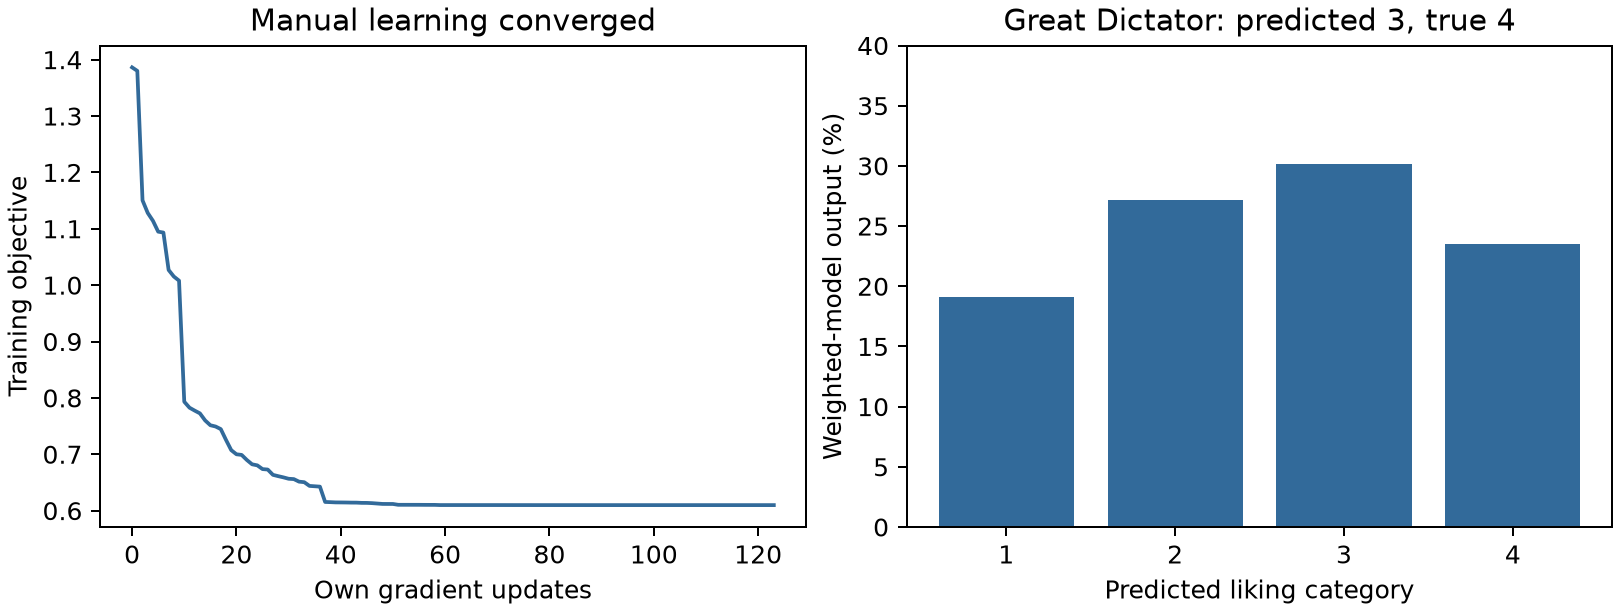

,gradient_updates,final_max_gradient,predicted_rating,true_rating
0,123,4.198814e-07,3,4


In [2]:
# A falling optimization loss is not a held-out prediction success.
import matplotlib.pyplot as plt
worked=json.loads((ROOT / "results/v2/worked_example.json").read_text())
fig,axes=plt.subplots(1,2,figsize=(9,3.4),layout="constrained")
axes[0].plot(worked["optimization_loss_history"],color="#326a9a")
axes[0].set(xlabel="Own gradient updates",ylabel="Training objective",
            title="Manual learning converged")
probabilities=[worked["probabilities"][str(k)]*100 for k in [1,2,3,4]]
axes[1].bar([1,2,3,4],probabilities,color="#326a9a")
axes[1].set(xticks=[1,2,3,4],xlabel="Predicted liking category",
            ylabel="Weighted-model output (%)",ylim=(0,40),
            title=f"Great Dictator: predicted {worked['predicted_rating']}, true 4")
path=ROOT / "results/v2/figures/manual_optimization.png"
fig.savefig(path,dpi=180);plt.close(fig)
display(Image(filename=str(path)))
display(pd.DataFrame({"gradient_updates":[len(worked["optimization_loss_history"])-1],
                      "final_max_gradient":[worked["optimization_final_max_gradient"]],
                      "predicted_rating":[worked["predicted_rating"]],"true_rating":[4]}))
